# Assignment 2. Quantization for CNN

> ### 이 노트북 읽는 법
> 이 파일은 `2. Quantization for CNN_answer.ipynb`에 **파이썬 초보자용 해설**을 덧붙인 버전입니다.
> - 원본의 셀(설명·코드·실행 결과)은 **그대로** 두었습니다.
> - 번호가 붙은 코드 셀 **바로 아래**마다 `📘 셀 N 해설` 칸을 추가했습니다. 맨 앞 **Setup 부분(셀 1 ~ 11)은 해설을 생략**했고, 본문인 셀 12 ~ 57을 설명합니다.
> - 해설은 **한 줄 요약 → 코드 뜯어보기 → 출력/그래프 해석** 순서입니다. 코드와 실행 결과를 먼저 훑어본 뒤 해설을 읽으면 이해하기 쉽습니다.
>
> **Setup에서 만들어 두고 뒤에서 계속 쓰는 것들**
> - `model` : CIFAR-10으로 학습을 마친 VGG 모델 / `recover_model()` : 모델 가중치를 원본으로 되돌리는 함수
> - `dataloader['train']`, `dataloader['test']` : 데이터를 묶음 단위로 꺼내 주는 도구. 이 노트북의 `dataloader['test']`는 **100장**(클래스당 10장)만 사용합니다.
> - `evaluate(model, dataloader)` : 정확도(%)를 재는 함수 / `get_model_size(model, 비트수)`, `MiB` : 모델 크기 계산용
> - `trainloader`, `testloader`, `train_model()`, `evaluate_model()` : 2.3절(PyTorch API)에서 쓰는 데이터와 학습·평가 함수
> - `qconfig_printer()` : 양자화 설정 내용을 출력하는 함수
>
> **미리 알아 둘 용어**
> - **양자화(Quantization)** : 32비트 실수로 저장된 값을 8비트 정수처럼 **더 적은 비트**로 바꿔 모델을 작고 빠르게 만드는 기법
> - **FP32 / int8** : 32비트 실수 / 8비트 정수(-128 ~ 127)
> - **scale($S$), zero point($Z$)** : 실수와 정수를 서로 바꾸는 규칙 $r = S(q - Z)$에 쓰이는 두 숫자
> - **가중치(weight)** : 모델이 학습으로 얻은 숫자 / **activation(feature)** : 층과 층 사이를 흐르는 중간 계산 값
> - **텐서(Tensor)** : PyTorch에서 쓰는 다차원 숫자 배열

## Goals

본 실습에서는 CNN(Convolutional Neural Network)을 **양자화(Quantization)**하여 모델의 크기와 실행 시간을 줄이는 방법을 실습합니다.

## Contents
1. **Uniform Quantization**
  - **Linear quantization**을 구현하고 적용합니다.
  - **Linear quantization**을 위한 **Integer-only inference**를 구현하고 적용합니다.
2. **Non-uniform Quantization**
  - **K-means quantization**을 구현하고 적용합니다.
3. **Quantization with PyTorch API**
  - **Post-Training Quantization** (PTQ)
  - **Quantization-Aware Training** (QAT)

## Setup

먼저, 필요한 패키지를 설치하고 데이터셋과 사전 학습된 모델을 다운로드합니다. 여기서는 CIFAR10 데이터셋과 VGG 네트워크를 사용할 것입니다.

In [1]:
# 1
import subprocess

print('Installing torchprofile...')
subprocess.check_call(["pip", "install", "torchprofile"])
print('Installing fast-pytorch-kmeans...')
subprocess.check_call(["pip", "install", "fast-pytorch-kmeans"])
print('All required packages have been successfully installed!')

Installing torchprofile...
Installing fast-pytorch-kmeans...
All required packages have been successfully installed!


In [2]:
# 2
import copy
import math
import random
from collections import OrderedDict, defaultdict

from matplotlib import pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
from tqdm.auto import tqdm

import torch
from torch import nn
from torch.optim import *
from torch.optim.lr_scheduler import *
from torch.utils.data import DataLoader
from torchprofile import profile_macs
from torchvision.datasets import *
from torchvision.transforms import *

In [3]:
# 3
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)

In [4]:
# 4
class VGG(nn.Module):
  ARCH = [64, 128, 'M', 256, 256, 'M', 512, 512, 'M', 512, 512, 'M']

  def __init__(self) -> None:
    super().__init__()

    layers = []
    counts = defaultdict(int)

    def add(name: str, layer: nn.Module) -> None:
      layers.append((f"{name}{counts[name]}", layer))
      counts[name] += 1

    in_channels = 3
    for x in self.ARCH:
      if x != 'M':
        # conv-bn-relu
        add("conv", nn.Conv2d(in_channels, x, 3, padding=1, bias=False))
        add("bn", nn.BatchNorm2d(x))
        add("relu", nn.ReLU(True))
        in_channels = x
      else:
        # maxpool
        add("pool", nn.MaxPool2d(2))
    add("avgpool", nn.AvgPool2d(2))
    self.backbone = nn.Sequential(OrderedDict(layers))
    self.classifier = nn.Linear(512, 10)

  def forward(self, x: torch.Tensor) -> torch.Tensor:
    # backbone: [N, 3, 32, 32] => [N, 512, 2, 2]
    x = self.backbone(x)

    # avgpool: [N, 512, 2, 2] => [N, 512]
    # x = x.mean([2, 3])
    x = x.view(x.shape[0], -1)

    # classifier: [N, 512] => [N, 10]
    x = self.classifier(x)
    return x

In [5]:
# 5
# import torch.nn as nn
# import torch.optim as optim
# import torchvision
# import torchvision.transforms as transforms
# from torch.utils.data import DataLoader

# # CIFAR-10 데이터셋 로드 및 전처리
# transform = transforms.Compose(
#     [transforms.ToTensor(), transforms.Normalize(mean=[0.4914, 0.4822, 0.4465], std=[0.2023, 0.1994, 0.2010])]
# )
# trainset = torchvision.datasets.CIFAR10(
#     root="D:\\data", train=True, download=True, transform=transform
# )
# testset = torchvision.datasets.CIFAR10(
#     root="D:\\data", train=False, download=True, transform=transform
# )

# trainloader = DataLoader(trainset, batch_size=1024, shuffle=True)
# testloader = DataLoader(testset, batch_size=100, shuffle=False)

# # 모델 학습 함수 정의
# def train_model(model, trainloader, epochs=5):
#     try:
#         device = next(model.parameters()).device
#     except StopIteration:
#         try:
#             device = next(model.buffers()).device
#         except StopIteration:
#             # 파라미터나 버퍼가 모두 없으면 기본적으로 CPU로 설정
#             device = torch.device("cpu")
#     optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
#     criterion = nn.CrossEntropyLoss()

#     model.train()

#     for epoch in range(epochs):
#         running_loss = 0.0
#         for inputs, labels in trainloader:
#             inputs, labels = inputs.to(device), labels.to(device)
#             optimizer.zero_grad()
#             outputs = model(inputs)
#             loss = criterion(outputs, labels)
#             loss.backward()
#             optimizer.step()
#             running_loss += loss.item()
#         print(f"Epoch [{epoch+1}/{epochs}], Loss: {running_loss/len(trainloader):.4f}")
#     return model

# # 모델 평가 함수 정의
# def evaluate_model(model, testloader):
#     try:
#         device = next(model.parameters()).device
#     except StopIteration:
#         try:
#             device = next(model.buffers()).device
#         except StopIteration:
#             # 파라미터나 버퍼가 모두 없으면 기본적으로 CPU로 설정
#             device = torch.device("cpu")
#     model.eval()
#     correct = 0
#     total = 0
#     with torch.no_grad():
#         for inputs, labels in testloader:
#             inputs, labels = inputs.to(device), labels.to(device)
#             outputs = model(inputs)
#             _, predicted = torch.max(outputs, 1)
#             total += labels.size(0)
#             correct += (predicted == labels).sum().item()
#     accuracy = 100 * correct / total
#     return accuracy

import torch
import torch.nn as nn
import torch.optim as optim

import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset


# CIFAR-10 데이터셋 로드 및 전처리
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.4914, 0.4822, 0.4465],
        std=[0.2023, 0.1994, 0.2010],
    )
])


class HFCIFAR10(Dataset):
    def __init__(self, split, transform=None):
        self.dataset = load_dataset("uoft-cs/cifar10", split=split)
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        item = self.dataset[idx]

        # Hugging Face CIFAR-10 field names: img, label
        image = item["img"].convert("RGB")
        label = item["label"]

        if self.transform is not None:
            image = self.transform(image)

        return image, label


trainset = HFCIFAR10(split="train", transform=transform)
testset = HFCIFAR10(split="test", transform=transform)

trainloader = DataLoader(trainset, batch_size=1024, shuffle=True)
testloader = DataLoader(testset, batch_size=100, shuffle=False)


# 모델 학습 함수 정의
def train_model(model, trainloader, epochs=5):
    try:
        device = next(model.parameters()).device
    except StopIteration:
        try:
            device = next(model.buffers()).device
        except StopIteration:
            device = torch.device("cpu")

    optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
    criterion = nn.CrossEntropyLoss()

    model.train()

    for epoch in range(epochs):
        running_loss = 0.0

        for inputs, labels in trainloader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f"Epoch [{epoch+1}/{epochs}], Loss: {running_loss / len(trainloader):.4f}")

    return model


# 모델 평가 함수 정의
def evaluate_model(model, testloader):
    try:
        device = next(model.parameters()).device
    except StopIteration:
        try:
            device = next(model.buffers()).device
        except StopIteration:
            device = torch.device("cpu")

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    return accuracy

In [6]:
# 6
@torch.inference_mode()
def evaluate(
  model: nn.Module,
  dataloader: DataLoader,
  extra_preprocess = None
) -> float:
  model.eval()

  num_samples = 0
  num_correct = 0

  for inputs, targets in tqdm(dataloader, desc="eval", leave=False):
    # Move the data from CPU to GPU
    if torch.cuda.is_available():
      inputs = inputs.cuda()
      targets = targets.cuda()
    if extra_preprocess is not None:
        for preprocess in extra_preprocess:
            inputs = preprocess(inputs)

    # Inference
    outputs = model(inputs)

    # Convert logits to class indices
    outputs = outputs.argmax(dim=1)

    # Update metrics
    num_samples += targets.size(0)
    num_correct += (outputs == targets).sum()

  return (num_correct / num_samples * 100).item()

Helpler Functions (Flops, Model Size calculation, etc.)

In [7]:
# 7
def get_model_flops(model, inputs):
    num_macs = profile_macs(model, inputs)
    return num_macs

In [8]:
# 8
def get_model_size(model: nn.Module, data_width=32):
    """
    calculate the model size in bits
    :param data_width: #bits per element
    """
    num_elements = 0
    for param in model.parameters():
        num_elements += param.numel()
    return num_elements * data_width

Byte = 8
KiB = 1024 * Byte
MiB = 1024 * KiB
GiB = 1024 * MiB

Define misc funcions for verification.

Load Pretrained Model

In [9]:
# 9
!curl -L "https://www.dropbox.com/scl/fi/ui1fkdvwlhd55fncto8fa/vgg_cifar10_pretrained.pth?rlkey=gu58eq42mo9riot1mexijw79k&st=gak0oq04&dl=1" -o "D:\\data\\vgg_cifar10_pretrained.pth"
checkpoint = torch.load('D:\\data\\vgg_cifar10_pretrained.pth', map_location="cpu")
model = VGG().cuda()
print(f"=> loading checkpoint 'vgg_cifar10_pretrained.pth'")
model.load_state_dict(checkpoint['state_dict'])
recover_model = lambda : model.load_state_dict(checkpoint['state_dict'])

#TORCH_HUB_REPO = "SKKU-ESLAB/pytorch-models"
#MODEL_NAME = "cifar10_vgg9_bn" # cifar10_resnet20, cifar10_vgg11_bn
#
#model = torch.hub.load(TORCH_HUB_REPO, MODEL_NAME, pretrained=True)
#if torch.cuda.is_available():
#    model = model.cuda()

  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed

  0      0   0      0   0      0      0      0                              0
100     17 100     17   0      0     31      0                              0
100     17 100     17   0      0     31      0                              0

  0      0   0      0   0      0      0      0                              0
100    496   0    496   0      0    396      0           00:01              0
100    496   0    496   0      0    396      0           00:01              0

  0      0   0      0   0      0      0      0           00:01              0
 34 35.23M  34 12.07M   0      0  5.31M      0   00:06   00:02   00:04 11.85M
100 35.23M 100 35.23M   0      0 11.59M      0   00:03   00:03         11.85M
100 35.23M 100 35.23M   0      0 11.59M      0   00:03   00:03         11.85M
100 35.23M 100 35.23M   0      0 11.59M      0   00:03   00:0

=> loading checkpoint 'vgg_cifar10_pretrained.pth'


In [10]:
# 10
# from torch.utils.data import Subset
# import numpy as np

# image_size = 32
# transforms = {
#     "train": Compose([
#         RandomCrop(image_size, padding=4),
#         RandomHorizontalFlip(),
#         ToTensor(),
#     ]),
#     "test": ToTensor(),
# }

# dataset = {}
# for split in ["train", "test"]:
#     dataset[split] = CIFAR10(
#         root="D:\\data\\cifar10",
#         train=(split == "train"),
#         download=True,
#         transform=transforms[split],
#     )


# num_classes = 10
# targets = np.array(dataset['test'].targets)

# indices = []
# for class_idx in range(num_classes):
#     class_indices = np.where(targets == class_idx)[0]
#     selected_indices = np.random.choice(class_indices, len(class_indices) // 100, replace=False)
#     indices.extend(selected_indices)

# dataset['test'] = Subset(dataset['test'], indices)

# dataloader = {}
# for split in ['train', 'test']:
#     dataloader[split] = DataLoader(
#         dataset[split],
#         batch_size=512,
#         shuffle=(split == 'train'),
#         num_workers=0,
#         pin_memory=True,
#     )
import numpy as np

from datasets import load_dataset

from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.transforms import Compose, RandomCrop, RandomHorizontalFlip, ToTensor


class HFCIFAR10(Dataset):
    def __init__(self, split, transform=None):
        self.data = load_dataset("uoft-cs/cifar10", split=split)
        self.transform = transform
        self.targets = list(self.data["label"])

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        # Subset에서 numpy.int64가 들어올 수 있으므로 Python int로 변환
        idx = int(idx)

        item = self.data[idx]

        image = item["img"].convert("RGB")
        label = item["label"]

        if self.transform is not None:
            image = self.transform(image)

        return image, label


image_size = 32

transforms = {
    "train": Compose([
        RandomCrop(image_size, padding=4),
        RandomHorizontalFlip(),
        ToTensor(),
    ]),
    "test": ToTensor(),
}

dataset = {}
for split in ["train", "test"]:
    dataset[split] = HFCIFAR10(
        split=split,
        transform=transforms[split],
    )


num_classes = 10
targets = np.array(dataset["test"].targets)

indices = []
for class_idx in range(num_classes):
    class_indices = np.where(targets == class_idx)[0]

    selected_indices = np.random.choice(
        class_indices,
        len(class_indices) // 100,
        replace=False,
    )

    indices.extend(selected_indices)

dataset["test"] = Subset(dataset["test"], indices)


dataloader = {}
for split in ["train", "test"]:
    dataloader[split] = DataLoader(
        dataset[split],
        batch_size=512,
        shuffle=(split == "train"),
        num_workers=0,
        pin_memory=True,
    )

In [11]:
# 11
def qconfig_printer(qconfig):
    # 가중치(weight) 관찰자 인스턴스 생성 및 속성 조회
    weight_observer_instance = qconfig.weight()
    weight_observer = weight_observer_instance.__class__.__name__
    weight_dtype = weight_observer_instance.dtype
    weight_qscheme = weight_observer_instance.qscheme
    weight_quant_min = weight_observer_instance.quant_min
    weight_quant_max = weight_observer_instance.quant_max

    # 활성화(activation) 관찰자 인스턴스 생성 및 속성 조회
    activation_observer_instance = qconfig.activation()
    activation_observer = activation_observer_instance.__class__.__name__
    activation_dtype = activation_observer_instance.dtype
    activation_qscheme = activation_observer_instance.qscheme
    activation_quant_min = activation_observer_instance.quant_min
    activation_quant_max = activation_observer_instance.quant_max


    # 결과 출력
    print(f"Weight Observer: {weight_observer}")
    print(f"Weight dtype: {weight_dtype}")
    print(f"Weight qscheme: {weight_qscheme}")
    print(f"Weight quant_min: {weight_quant_min}")
    print(f"Weight quant_max: {weight_quant_max}")
    print("----------------------------------------------")
    print(f"Activation Observer: {activation_observer}")
    print(f"Activation dtype: {activation_dtype}")
    print(f"Activation qscheme: {activation_qscheme}")
    print(f"Activation quant_min: {activation_quant_min}")
    print(f"Activation quant_max: {activation_quant_max}")

# 2.1. Linear Quantization

이 섹션에서는 linear quantization을 구현하고 수행할 것입니다.

Linear quantization은 range truncation 및 scaling 후에 부동 소수점 실수값을 가장 가까운 정수로 반올림합니다.

[Linear quantization](https://arxiv.org/pdf/1712.05877.pdf) 은 다음과 같이 표현할 수 있습니다:

$r = S(q-Z)$

여기서 $r$ 과 $S$은 부동 소수점 실수이며, $q$ 와 $Z$ 는 *n*-bit 정수입니다. $Z$ 는 quantization zero point를 의미하며, $S$ 는 quantization scaling factor입니다. 상수 $Z$ 와 $S$ 는 quantization parameter 입니다.

먼저 FP32(32비트 부동 소수점) 모델의 정확도와 모델 크기를 평가해봅시다.

In [12]:
# 12
fp32_model_accuracy = evaluate(model, dataloader['test'])
fp32_model_size = get_model_size(model)
print(f"fp32 model의 정확도={fp32_model_accuracy:.2f}%")
print(f"fp32 model의 크기={fp32_model_size/MiB:.2f} MiB")

eval:   0%|          | 0/1 [00:00<?, ?it/s]

fp32 model의 정확도=93.00%
fp32 model의 크기=35.20 MiB


### 📘 셀 12 해설
**한 줄 요약:** 양자화하기 **전** 원본 모델(FP32)의 정확도와 크기를 재서 기준점으로 삼습니다.

- `evaluate(model, dataloader['test'])` : Setup에서 만든 평가 함수로 정확도(%)를 계산합니다.
- `get_model_size(model)` : 가중치 개수 × 32비트 = 모델 전체 비트 수
- `fp32_model_size/MiB` : Setup에서 `MiB = 1024 * 1024 * 8`(비트)로 정의해 두었으므로, 나누면 MiB 단위가 됩니다.
- f-string의 `{값:.2f}` : 소수점 둘째 자리까지 출력

**용어:** **FP32** = 32비트 부동소수점(실수). 가중치 1개를 32비트로 저장하는 보통의 모델입니다. **양자화(Quantization)** 는 이것을 8비트 정수처럼 더 적은 비트로 바꾸는 기술입니다.

**출력 해석:** 정확도 `93.00%`, 크기 `35.20 MiB`

> 정확도가 소수점 없이 딱 떨어지는 이유: 이 노트북의 Setup에서 테스트 데이터를 **클래스당 10장, 총 100장**만 뽑아 쓰도록 줄여 놓았기 때문입니다. 따라서 **1장 = 1%p**이고, 뒤에서 나오는 1~2%p 차이는 이미지 1~2장 차이라는 점을 기억해 두세요.

## *n*-bit integer

*n*-bit signed integer 는 일반적으로 [2의 보수](https://ko.wikipedia.org/wiki/2%EC%9D%98_%EB%B3%B4%EC%88%98)로 표현됩니다.

*n*-bit signed integer는 정수 범위 $[-2^{n-1}, 2^{n-1}-1]$를 인코딩할 수 있습니다. 예를 들어, 8-bit integer는 범위 [-128, 127] 에 해당합니다.

In [13]:
# 13
def get_quantized_range(bitwidth):
    quantized_max = (1 << (bitwidth - 1)) - 1
    quantized_min = -(1 << (bitwidth - 1))
    return quantized_min, quantized_max

### 📘 셀 13 해설
**한 줄 요약:** n비트 정수가 표현할 수 있는 **최솟값과 최댓값**을 돌려주는 함수입니다.

- `1 << (bitwidth - 1)` : `<<`는 **비트를 왼쪽으로 미는 연산**으로, `1 << k`는 2의 k제곱과 같습니다. 예) `1 << 7` = 128
- `quantized_max = 2^(n-1) - 1`, `quantized_min = -2^(n-1)`
- `return quantized_min, quantized_max` : 값 2개를 한꺼번에(튜플로) 돌려줍니다. 받을 때는 `qmin, qmax = get_quantized_range(8)`처럼 씁니다.

| bitwidth | 범위 | 표현 가능한 값의 개수 |
|---|---|---|
| 8 | -128 ~ 127 | 256개 |
| 4 | -8 ~ 7 | 16개 |
| 2 | -2 ~ 1 | 4개 |

## [실습 1] Linear quantization 구현

다음 linear quantization 함수를 완성해 주세요.

**Hint**:
*   $r=S(q-Z)$ 로 부터, $q = r/S + Z$ 를 도출할 수 있습니다.
*   $r$ 과 $S$ 는 모두 부동 소수점이므로, 정수 $Z$ 을 부동 소수점 $r/S$ 에 직접 더할 수 없습니다. 그러므로 $q = \mathrm{int}(\mathrm{round}(r/S)) + Z$ 와 같이 계산해야 합니다.
*   [`torch.FloatTensor`](https://pytorch.org/docs/stable/tensors.html) 에서 [`torch.IntTensor`](https://pytorch.org/docs/stable/tensors.html) 로 변환하려면, 먼저 [`torch.round()`](https://pytorch.org/docs/stable/generated/torch.round.html#torch.round), [`torch.Tensor.round()`](https://pytorch.org/docs/stable/generated/torch.Tensor.round.html#torch.Tensor.round), 또는 [`torch.Tensor.round_()`](https://pytorch.org/docs/stable/generated/torch.Tensor.round_)을 사용하여 모든 값을 부동 소수점 정수로 반올림 한 후, [`torch.Tensor.to(torch.int8)`](https://pytorch.org/docs/stable/generated/torch.Tensor.to.html#torch.Tensor.to) 를 사용하여 데이터 유형을 [`torch.float`](https://pytorch.org/docs/stable/tensors.html) 에서 [`torch.int8`](https://pytorch.org/docs/stable/tensors.html)로 변환해야 합니다.



In [14]:
# 14
def linear_quantize(fp_tensor, bitwidth, scale, zero_point, dtype=torch.int8) -> torch.Tensor:
    """
    linear quantization for single fp_tensor
      from
        fp_tensor = (quantized_tensor - zero_point) * scale
      we have,
        quantized_tensor = int(round(fp_tensor / scale)) + zero_point
    :param tensor: [torch.(cuda.)FloatTensor] floating tensor to be quantized
    :param bitwidth: [int] quantization bit width
    :param scale: [torch.(cuda.)FloatTensor] scaling factor
    :param zero_point: [torch.(cuda.)IntTensor] the desired centroid of tensor values
    :return:
        [torch.(cuda.)FloatTensor] quantized tensor whose values are integers
    """
    assert(fp_tensor.dtype == torch.float)
    assert(isinstance(scale, float) or
           (scale.dtype == torch.float and scale.dim() == fp_tensor.dim()))
    assert(isinstance(zero_point, int) or
           (zero_point.dtype == dtype and zero_point.dim() == fp_tensor.dim()))

    ############### YOUR CODE STARTS HERE ###############
    # Step 1: fp_tensor를 scale 하세요.
    scaled_tensor = fp_tensor/scale
    # Step 2: 부동 소수점 값을 정수 값으로 rounding 하세요.
    rounded_tensor = torch.round(scaled_tensor)
    ############### YOUR CODE ENDS HERE #################

    rounded_tensor = rounded_tensor.to(dtype)

    ############### YOUR CODE STARTS HERE ###############
    # Step 3: rounded_tensor를 zero_point 만큼 shift하여 영점을 조정합니다.
    shifted_tensor = rounded_tensor + zero_point
    ############### YOUR CODE ENDS HERE #################

    # Step 4: shifted_tensor를 bitwidth 범위에 있도록 절사(clamp)합니다.
    quantized_min, quantized_max = get_quantized_range(bitwidth)
    quantized_tensor = shifted_tensor.clamp_(quantized_min, quantized_max)
    return quantized_tensor

### 📘 셀 14 해설
**한 줄 요약:** [실습 1 정답] 실수 텐서를 **정수 텐서로 바꾸는** 선형 양자화 함수입니다. 공식은 $q = \mathrm{round}(r/S) + Z$ 입니다.

**기호 정리:** $r$ = 원래 실수 값, $q$ = 양자화된 정수 값, $S$(scale) = 정수 1칸이 실수로 얼마인지(눈금 간격), $Z$(zero point) = 실수 0에 대응하는 정수

**앞부분 `assert`** : "이 조건이 참이어야 한다"는 **검사문**입니다. 거짓이면 오류를 내고 멈춥니다. 여기서는 입력이 실수 텐서인지, scale과 zero_point의 형식이 맞는지를 확인합니다. `isinstance(x, float)`는 "x가 float 타입인가?"를 묻습니다.

**4단계 처리**

| 단계 | 코드 | 의미 |
|---|---|---|
| 1 (정답) | `scaled_tensor = fp_tensor/scale` | 눈금 간격으로 나눔 → "몇 칸째인가" |
| 2 (정답) | `rounded_tensor = torch.round(scaled_tensor)` | 가장 가까운 정수로 반올림 |
| - | `rounded_tensor.to(dtype)` | 자료형을 실제 정수형(`int8`)으로 변환 |
| 3 (정답) | `shifted_tensor = rounded_tensor + zero_point` | 영점만큼 이동 |
| 4 | `shifted_tensor.clamp_(quantized_min, quantized_max)` | 범위를 벗어난 값은 최솟값/최댓값으로 **잘라 맞춤** |

**직접 계산해 보기** (S = 1/3, Z = -1, 2비트 → 범위 -2 ~ 1)
- r = 0.6364 → 0.6364 ÷ (1/3) = 1.909 → 반올림 2 → 2 + (-1) = **1**
- r = -0.25 → -0.75 → 반올림 -1 → -1 + (-1) = **-2**

> `clamp_`처럼 이름 끝에 `_`가 붙은 PyTorch 함수는 새 텐서를 만들지 않고 **그 텐서 자체를 수정**합니다.

정의된 linear quantization 함수의 기능을 확인하기 위해 더미 텐서에 위의 함수를 적용해 보겠습니다.

In [15]:
# 15
def test_linear_quantize(
    test_tensor=torch.tensor([
        [ 0.0523,  0.6364, -0.0968, -0.0020,  0.1940],
        [ 0.7500,  0.5507,  0.6188, -0.1734,  0.4677],
        [-0.0669,  0.3836,  0.4297,  0.6267, -0.0695],
        [ 0.1536, -0.0038,  0.6075,  0.6817,  0.0601],
        [ 0.6446, -0.2500,  0.5376, -0.2226,  0.2333]]),
    quantized_test_tensor=torch.tensor([
        [-1,  1, -1, -1,  0],
        [ 1,  1,  1, -2,  0],
        [-1,  0,  0,  1, -1],
        [-1, -1,  1,  1, -1],
        [ 1, -2,  1, -2,  0]], dtype=torch.int8),
    real_min=-0.25, real_max=0.75, bitwidth=2, scale=1/3, zero_point=-1):
    def plot_matrix(tensor, ax, title, vmin=0, vmax=1, cmap=ListedColormap(['white'])):
        ax.imshow(tensor.cpu().numpy(), vmin=vmin, vmax=vmax, cmap=cmap)
        ax.set_title(title)
        ax.set_yticklabels([])
        ax.set_xticklabels([])
        for i in range(tensor.shape[0]):
            for j in range(tensor.shape[1]):
                datum = tensor[i, j].item()
                if isinstance(datum, float):
                    text = ax.text(j, i, f'{datum:.2f}',
                                    ha="center", va="center", color="k")
                else:
                    text = ax.text(j, i, f'{datum}',
                                    ha="center", va="center", color="k")
    quantized_min, quantized_max = get_quantized_range(bitwidth)
    fig, axes = plt.subplots(1,3, figsize=(10, 32))
    plot_matrix(test_tensor, axes[0], 'original tensor', vmin=real_min, vmax=real_max)
    _quantized_test_tensor = linear_quantize(
        test_tensor, bitwidth=bitwidth, scale=scale, zero_point=zero_point)
    _reconstructed_test_tensor = scale * (_quantized_test_tensor.float() - zero_point)
    print('* Test linear_quantize()')
    print(f'    target bitwidth: {bitwidth} bits')
    print(f'        scale: {scale}')
    print(f'        zero point: {zero_point}')
    assert _quantized_test_tensor.equal(quantized_test_tensor)
    print('* Test passed.')
    plot_matrix(_quantized_test_tensor, axes[1], f'2-bit linear quantized tensor',
                vmin=quantized_min, vmax=quantized_max, cmap='tab20c')
    plot_matrix(_reconstructed_test_tensor, axes[2], f'reconstructed tensor',
                vmin=real_min, vmax=real_max, cmap='tab20c')
    fig.tight_layout()
    plt.show()

### 📘 셀 15 해설
**한 줄 요약:** 방금 만든 `linear_quantize()`가 올바른지 **정답과 비교하고 그림으로 보여 주는** 테스트 함수입니다. (정의만 하고, 실행은 다음 셀)

- **기본값이 있는 인자** : `def f(a=1, b=2)`처럼 적으면, 호출할 때 값을 안 줘도 기본값이 쓰입니다. 여기서는 테스트용 5×5 텐서(`test_tensor`)와 **기대 정답**(`quantized_test_tensor`)이 기본값으로 들어 있습니다.
- **함수 안의 함수** `plot_matrix` : 텐서를 격자 그림으로 그리고 칸마다 숫자를 적어 주는 보조 함수입니다. 이중 `for`문(`i`=행, `j`=열)으로 모든 칸을 돌며 `ax.text`로 글자를 씁니다.
- `_quantized_test_tensor = linear_quantize(...)` : 우리 함수로 양자화
- `_reconstructed_test_tensor = scale * (_quantized_test_tensor.float() - zero_point)` : 공식 $r = S(q - Z)$로 **다시 실수로 복원**
- `assert _quantized_test_tensor.equal(quantized_test_tensor)` : 결과가 정답과 **완전히 같은지** 검사. 다르면 여기서 오류가 납니다.
- `plt.subplots(1, 3, ...)` : 그림 3칸(원본 / 양자화 결과 / 복원 결과)

* Test linear_quantize()
    target bitwidth: 2 bits
        scale: 0.3333333333333333
        zero point: -1
* Test passed.


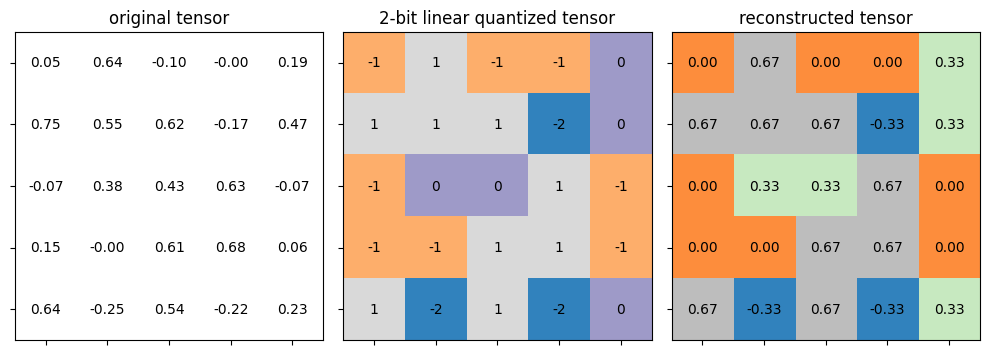

In [16]:
# 16
test_linear_quantize()

### 📘 셀 16 해설
**한 줄 요약:** 테스트를 실행합니다. `* Test passed.`가 나오면 실습 1의 구현이 정답과 일치한다는 뜻입니다.

**그림 해석** (2비트이므로 정수는 -2, -1, 0, 1 네 가지뿐)
- **왼쪽(original)** : 원래 실수 값 25개가 모두 다릅니다.
- **가운데(quantized)** : 모든 값이 -2, -1, 0, 1 중 하나로 바뀌었습니다. 같은 값은 같은 색입니다.
- **오른쪽(reconstructed)** : 정수를 다시 실수로 되돌린 값입니다. $S(q-Z) = (q+1)/3$ 이므로 **-0.33, 0, 0.33, 0.67** 네 가지만 나옵니다.

원본 0.6364가 0.67로, 0.0523이 0으로 바뀐 것처럼, 복원해도 원래 값과 조금씩 다릅니다. 이 차이가 **양자화 오차**이며, 비트 수가 적을수록 커집니다.

이제 linear quantization을 위한 scaling factor $S$ 와 zero point $Z$ 을 결정해야 합니다.

[Linear quantization](https://arxiv.org/pdf/1712.05877.pdf) 은 다음과 같이 표현될 수 있습니다:

$r = S(q-Z)$

### Scale

Linear quantization은 floating point range [*fp_min*, *fp_max*] 를 quantized range [*quantized_min*, *quantized_max*] 로 매핑합니다. 즉, 다음과 같이 표현할 수 있습니다:

> $r_{\mathrm{max}} = S(q_{\mathrm{max}}-Z)$
>
> $r_{\mathrm{min}} = S(q_{\mathrm{min}}-Z)$

이 두 방정식을 빼면, $S=(r_{\mathrm{max}} - r_{\mathrm{min}}) / (q_{\mathrm{max}} - q_{\mathrm{min}})$ 를 얻을 수 있습니다.


부동 소수점 텐서 `fp_tensor`의 $r_{\mathrm{min}}$ and  $r_{\mathrm{max}}$ 를 결정하는 데는 여러가지 접근 방법이 있습니다.

*  가장 일반적인 방법은 `fp_tensor`의 최소값과 최대값을 직접 사용하는 것입니다.
*  또 다른 방법은 쿨백-라이블러 발산(Kullback-Leibler-J divergence)을 최소화하여 *fp_max*를 결정하는 것입니다.

### zero point

Scaling factor $S$ 를 결정한 후, $r_{\mathrm{min}}$ 과 $q_{\mathrm{min}}$ 의 관계를 직접 사용하여 zero point $Z$ 를 계산할 수 있습니다.

> $Z = \mathrm{int}(\mathrm{round}(q_{\mathrm{min}} - r_{\mathrm{min}} / S))$

# [실습 2] Scale 및 zero point 계산

부동 소수점 텐서 $r$ 에서 scale $S$ 와 zero point $Z$ 을 계산하는 다음 함수를 완성해 주세요.

In [17]:
# 17
def get_quantization_scale_and_zero_point(fp_tensor, bitwidth):
    """
    get quantization scale for single tensor
    :param fp_tensor: [torch.(cuda.)Tensor] floating tensor to be quantized
    :param bitwidth: [int] quantization bit width
    :return:
        [float] scale
        [int] zero_point
    """
    quantized_min, quantized_max = get_quantized_range(bitwidth)
    fp_max = fp_tensor.max().item()
    fp_min = fp_tensor.min().item()

    ############### YOUR CODE STARTS HERE ###############
    # hint: quantized_max - quantized_min = 2 ** bitwith - 1
    scale = (fp_max - fp_min) / (quantized_max - quantized_min)
    zero_point = round(quantized_min - fp_min/scale)
    ############### YOUR CODE ENDS HERE #################

    # clip the zero_point to fall in [quantized_min, quantized_max]
    if zero_point < quantized_min:
        zero_point = quantized_min
    elif zero_point > quantized_max:
        zero_point = quantized_max
    else: # convert from float to int using round()
        zero_point = round(zero_point)
    return scale, int(zero_point)

### 📘 셀 17 해설
**한 줄 요약:** [실습 2 정답] 텐서의 값 범위를 보고 알맞은 **scale($S$)과 zero point($Z$)를 계산**합니다.

**생각 방법:** 실수 범위 [fp_min, fp_max]를 정수 범위 [quantized_min, quantized_max]에 **끝과 끝이 맞도록** 대응시킵니다.

- `fp_tensor.max().item()` : 텐서의 최댓값을 파이썬 숫자로 꺼냄 (`min()`은 최솟값)
- **(정답)** `scale = (fp_max - fp_min) / (quantized_max - quantized_min)` : 실수 범위의 폭 ÷ 정수 범위의 폭 = 정수 1칸의 크기
- **(정답)** `zero_point = round(quantized_min - fp_min/scale)` : "fp_min이 quantized_min에 대응한다"는 조건에서 $Z$를 구함
- 뒤의 `if / elif / else` : 계산된 zero point가 정수 범위를 벗어나면 범위 안으로 잘라 맞춥니다.
- `return scale, int(zero_point)` : 값 2개를 돌려줌

**직접 계산해 보기** (셀 15의 테스트: fp_min = -0.25, fp_max = 0.75, 2비트 → -2 ~ 1)
- scale = (0.75 − (−0.25)) / (1 − (−2)) = 1 / 3
- zero_point = round(−2 − (−0.25 ÷ 1/3)) = round(−2 + 0.75) = round(−1.25) = **−1**

셀 15에서 주어진 `scale=1/3, zero_point=-1`과 정확히 일치합니다.

이제  실습 1의 `linear_quantize()`과 실습 2의 `get_quantization_scale_and_zero_point()`을 하나의 함수로 래핑합니다.

In [18]:
# 18
def linear_quantize_feature(fp_tensor, bitwidth):
    """
    linear quantization for feature tensor
    :param fp_tensor: [torch.(cuda.)Tensor] floating feature to be quantized
    :param bitwidth: [int] quantization bit width
    :return:
        [torch.(cuda.)Tensor] quantized tensor
        [float] scale tensor
        [int] zero point
    """
    scale, zero_point = get_quantization_scale_and_zero_point(fp_tensor, bitwidth)
    quantized_tensor = linear_quantize(fp_tensor, bitwidth, scale, zero_point)
    return quantized_tensor, scale, zero_point

### 📘 셀 18 해설
**한 줄 요약:** 실습 1·2의 함수를 묶어, **"scale·zero point 계산 → 양자화"를 한 번에** 해 주는 편의 함수입니다.

1. `get_quantization_scale_and_zero_point(...)`로 $S$, $Z$ 계산
2. `linear_quantize(...)`로 양자화
3. 양자화된 텐서, scale, zero point **3개를 함께** 돌려줌

이름의 `feature`는 **층과 층 사이를 흐르는 데이터(activation, feature map)** 를 뜻합니다. 이런 데이터는 값이 한쪽으로 치우친 경우가 많아(예: ReLU 뒤에는 0 이상만 존재) zero point가 필요한 **비대칭(asymmetric)** 방식을 씁니다.

## 특수 케이스 : 가중치 텐서의 Linear quantization

먼저 가중치 텐서의 분포를 살펴보겠습니다.

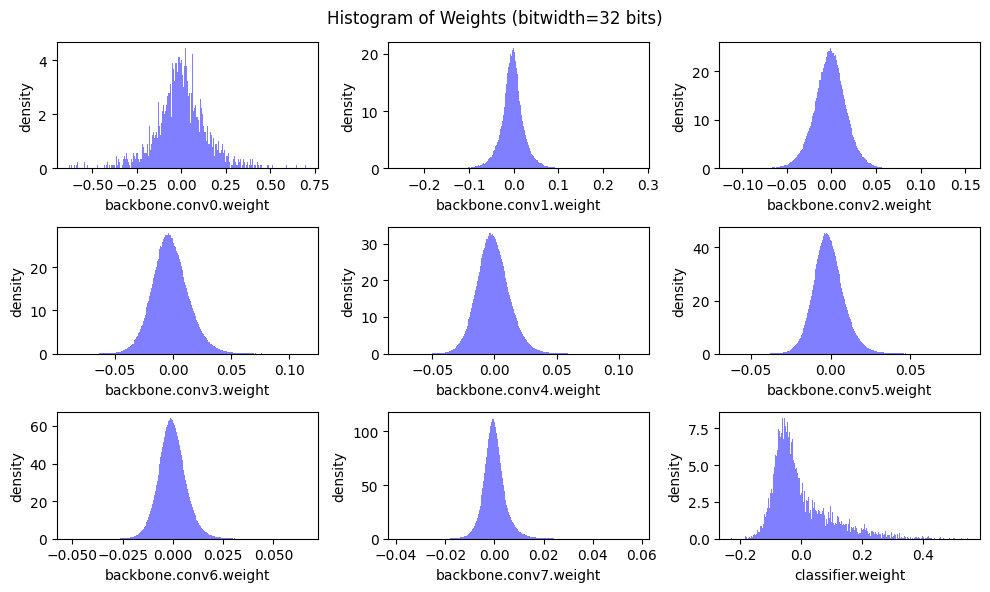

In [19]:
# 19
def plot_weight_distribution(model, bitwidth=32):
    # bins = (1 << bitwidth) if bitwidth <= 8 else 256
    if bitwidth <= 8:
        qmin, qmax = get_quantized_range(bitwidth)
        bins = np.arange(qmin, qmax + 2)
        align = 'left'
    else:
        bins = 256
        align = 'mid'
    fig, axes = plt.subplots(3,3, figsize=(10, 6))
    axes = axes.ravel()
    plot_index = 0
    for name, param in model.named_parameters():
        if param.dim() > 1:
            ax = axes[plot_index]
            ax.hist(param.detach().view(-1).cpu(), bins=bins, density=True,
                    align=align, color = 'blue', alpha = 0.5,
                    edgecolor='black' if bitwidth <= 4 else None)
            if bitwidth <= 4:
                quantized_min, quantized_max = get_quantized_range(bitwidth)
                ax.set_xticks(np.arange(start=quantized_min, stop=quantized_max+1))
            ax.set_xlabel(name)
            ax.set_ylabel('density')
            plot_index += 1
    fig.suptitle(f'Histogram of Weights (bitwidth={bitwidth} bits)')
    fig.tight_layout()
    fig.subplots_adjust(top=0.925)
    plt.show()

recover_model()
plot_weight_distribution(model)

### 📘 셀 19 해설
**한 줄 요약:** 층별 가중치 분포를 히스토그램으로 그리는 함수를 만들고, 원본 모델에 대해 그려 봅니다.

- `bitwidth <= 8`이면(양자화된 가중치) 정수 하나하나가 막대 하나가 되도록 `bins = np.arange(qmin, qmax + 2)`로 구간을 정수 단위로 만듭니다. 그 밖(원본 32비트)에는 256개 구간을 씁니다.
- `plt.subplots(3, 3)` + `axes.ravel()` : 3×3 = 9칸을 만들고 0~8번으로 한 줄로 폅니다(가중치 층이 9개).
- `if param.dim() > 1` : 2차원 이상인 파라미터(Conv, Linear의 weight)만 그립니다.
- `param.detach().view(-1).cpu()` : 값만 떼어 내(`detach`) 한 줄로 펴고(`view(-1)`) CPU로 옮김
- `'black' if bitwidth <= 4 else None` : **한 줄 if문**. 4비트 이하일 때만 막대 테두리를 검게 그립니다.

**실행 부분**
- `recover_model()` : Setup에서 만든 함수로, 모델 가중치를 **저장해 둔 원본으로 되돌립니다.** 실험 전에 항상 깨끗한 상태에서 시작하기 위해서입니다.
- `plot_weight_distribution(model)` : `bitwidth`를 생략했으므로 기본값 32가 쓰입니다.

**그래프 해석:** 대부분의 층에서 가중치가 **0을 중심으로 좌우 대칭**인 종 모양입니다(classifier 제외). 이 관찰이 다음 셀의 "가중치는 zero point를 0으로 둔다"는 결정의 근거가 됩니다.

위의 히스토그램에서 볼 수 있듯이, 가중치 값의 분포는 0을 중심으로 거의 대칭입니다(Classifier 제외).

따라서 일반적으로 가중치를 quantization 할 때 zeropoint $Z$를 0으로 설정합니다.

$r = S(q-Z)$ 로 부터, 우리는 다음을 도출 할 수 있습니다:

> $r_{\mathrm{max}} = S \cdot q_{\mathrm{max}}$

그러므로

> $S = r_{\mathrm{max}} / q_{\mathrm{max}}$

가중치 값의 최대 크기를 $r_{\mathrm{max}}$로 직접 사용합니다.

In [20]:
# 20
def get_quantization_scale_for_weight(weight, bitwidth):
    """
    get quantization scale for single tensor of weight
    :param weight: [torch.(cuda.)Tensor] floating weight to be quantized
    :param bitwidth: [integer] quantization bit width
    :return:
        [floating scalar] scale
    """
    # 가중치 텐서의 분포가 대칭이라고 가정합니다.
    # zeropoint를 0으로 설정합니다.
    fp_max = max(weight.abs().max().item(), 5e-7)
    _, quantized_max = get_quantized_range(bitwidth)
    return fp_max / quantized_max

### 📘 셀 20 해설
**한 줄 요약:** **가중치 전용** scale 계산 함수입니다. 분포가 0 중심 대칭이라고 보고 **zero point는 0으로 고정**, scale만 구합니다.

- `weight.abs().max().item()` : 절댓값이 가장 큰 가중치의 크기 = $r_{max}$
- `max(..., 5e-7)` : 두 값 중 큰 값. 가중치가 전부 0이면 scale이 0이 되어 나눗셈 오류가 나므로, 아주 작은 값(0.0000005)을 하한으로 둡니다.
- `_, quantized_max = get_quantized_range(bitwidth)` : 돌려받는 값 2개 중 첫 번째는 쓰지 않으므로 `_`(버리는 변수)로 받습니다.
- `return fp_max / quantized_max` : $S = r_{max} / q_{max}$

**예시:** 가중치의 최대 절댓값이 0.5이고 8비트라면 S = 0.5 / 127 ≈ 0.0039. 즉 정수 127이 실수 0.5에, 정수 -127이 -0.5에 대응합니다. 이렇게 zero point 없이 0을 중심으로 하는 방식을 **대칭(symmetric) 양자화**라고 합니다.

### Per-tensor Linear Quantization

먼저 가장 기초적인 방법인 Per-Tensor Quantization을 적용해보겠습니다.

Per-Tensor Quantization은 weight tensor $W$ 에 대해서 하나의 scaling factors $S$ 와 zero points $Z$를 결정합니다.

Per-Tensor Quantization은 구현이 쉽고 연산량이 적으며, 크기가 큰 모델에서 잘 작동합니다.

In [21]:
# 21
def linear_quantize_weight_per_tensor(tensor, bitwidth):
    """
    linear quantization for weight tensor
        using different scales and zero_points for different output channels
    :param tensor: [torch.(cuda.)Tensor] floating weight to be quantized
    :param bitwidth: [int] quantization bit width
    :return:
        [torch.(cuda.)Tensor] quantized tensor
        [torch.(cuda.)Tensor] scale tensor
        [int] zero point (which is always 0)
    """
    scale_value = get_quantization_scale_for_weight(tensor, bitwidth)

    scale = torch.tensor([scale_value], device=tensor.device)

    scale_shape = [1] * tensor.dim()
    scale_shape[0] = tensor.shape[0]
    scale_per_channel = scale.expand(scale_shape)
    quantized_tensor = linear_quantize(tensor, bitwidth, scale_per_channel, zero_point=0)

    return quantized_tensor, scale_per_channel, 0

### 📘 셀 21 해설
**한 줄 요약:** 가중치 텐서 **전체에 scale 하나**를 써서 양자화합니다(**Per-tensor**).

- `scale_value = get_quantization_scale_for_weight(tensor, bitwidth)` : 텐서 전체에서 scale 1개 계산
- `torch.tensor([scale_value], device=tensor.device)` : 그 숫자를 가중치와 같은 장치(GPU/CPU)의 텐서로 만듦
- `scale_shape = [1] * tensor.dim()` : 리스트에 `*`를 쓰면 반복입니다. 4차원 텐서면 `[1, 1, 1, 1]`
- `scale_shape[0] = tensor.shape[0]` → `[출력채널수, 1, 1, 1]`
- `scale.expand(scale_shape)` : 값 하나를 그 모양으로 **늘려 복사**합니다. 모든 채널이 **같은 값**을 갖습니다.
  - 굳이 모양을 맞추는 이유: 다음 셀의 per-channel 방식과 **같은 형식**으로 다루기 위해서이고, `linear_quantize`의 `assert`(scale의 차원 수 = 텐서의 차원 수)도 통과해야 하기 때문입니다.
- `linear_quantize(tensor, bitwidth, scale_per_channel, zero_point=0)` : zero point 0으로 양자화
- 돌려주는 값: (양자화된 텐서, scale, 0)

> 함수 설명문(docstring)에 "출력 채널마다 다른 scale을 사용"이라고 적혀 있지만 이는 다음 셀의 설명이 복사된 것으로, 이 함수는 **모든 채널에 같은 scale**을 씁니다.

### Per-channel Linear Quantization

2D convolution의 경우, 가중치 텐서는 (num_output_channels, num_input_channels, kernel_height, kernel_width) 형태의 4D tensor 입니다.

최근 연구에서는, 서로 다른 출력 채널에 대해 다른 scaling factors $S$ 와 zero points $Z$ 를 사용하는 것이 더 나은 성능을 발휘한다는 것을 보여줍니다.

따라서 각 출력 채널의 부분 텐서에 대한 scaling factor $S$ 와 zero point $Z$ 을 독립적으로 결정해야 합니다.

In [22]:
# 22
def linear_quantize_weight_per_channel(tensor, bitwidth):
    """
    linear quantization for weight tensor
        using different scales and zero_points for different output channels
    :param tensor: [torch.(cuda.)Tensor] floating weight to be quantized
    :param bitwidth: [int] quantization bit width
    :return:
        [torch.(cuda.)Tensor] quantized tensor
        [torch.(cuda.)Tensor] scale tensor
        [int] zero point (which is always 0)
    """
    dim_output_channels = 0
    num_output_channels = tensor.shape[dim_output_channels]
    scale = torch.zeros(num_output_channels, device=tensor.device)

    for oc in range(num_output_channels):
        _subtensor = tensor.select(dim_output_channels, oc)
        _scale = get_quantization_scale_for_weight(_subtensor, bitwidth)
        scale[oc] = _scale
    scale_shape = [1] * tensor.dim()
    scale_shape[dim_output_channels] = -1
    scale = scale.view(scale_shape)
    quantized_tensor = linear_quantize(tensor, bitwidth, scale, zero_point=0)
    return quantized_tensor, scale, 0

### 📘 셀 22 해설
**한 줄 요약:** **출력 채널마다 scale을 따로** 계산해서 양자화합니다(**Per-channel**).

- `num_output_channels = tensor.shape[0]` : 출력 채널(필터) 개수
- `scale = torch.zeros(num_output_channels, ...)` : 채널별 scale을 담을 빈 칸(0으로 채움)
- `for oc in range(num_output_channels):` 채널을 하나씩 돌면서
  - `tensor.select(0, oc)` : 0번 차원에서 `oc`번째 조각을 꺼냄 = **필터 한 개**의 가중치
  - 그 필터만의 scale을 계산해 `scale[oc]`에 저장
- `scale_shape[dim_output_channels] = -1` → `[-1, 1, 1, 1]`, `scale.view(scale_shape)` : 모양을 [채널수, 1, 1, 1]로 바꿈 (`-1`은 "알아서 계산")
- `linear_quantize(tensor, bitwidth, scale, zero_point=0)` : 모양이 [채널수, 1, 1, 1]인 scale로 나누면, **브로드캐스팅**(모양이 다른 텐서끼리 자동으로 맞춰 계산)에 의해 각 필터가 자기 scale로 나뉩니다.

**왜 더 좋을까?** 필터마다 가중치의 크기가 다릅니다. Per-tensor는 "가장 큰 필터" 기준으로 눈금을 잡기 때문에 값이 작은 필터는 정수 몇 개만 쓰게 됩니다. Per-channel은 필터마다 눈금을 따로 잡아 **주어진 정수 범위를 끝까지 활용**하므로 오차가 줄어듭니다.

이제 서로 4-bit 비트 폭으로 가중치에 per-tensor와 per-channel linear quantization을 각각 적용할 때의 가중치 분포를 살펴보겠습니다.

Per-Tensor Quantization:


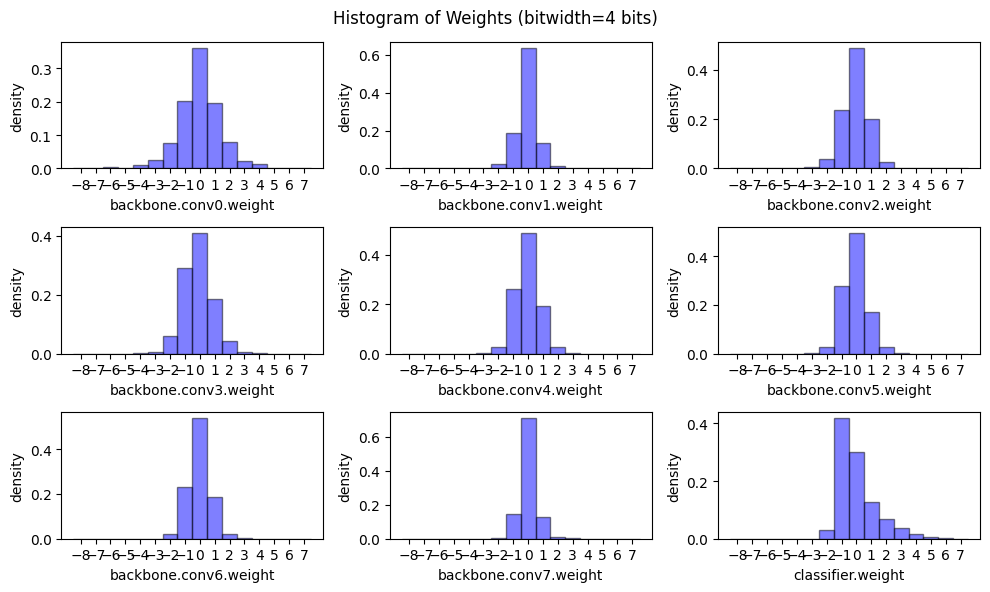

Per-Channel Quantization:


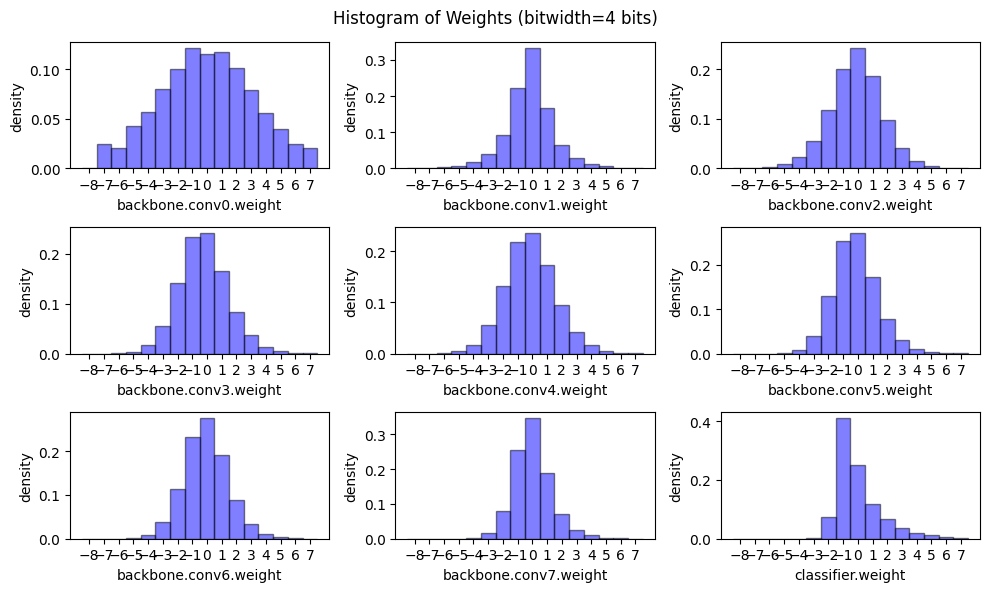

In [23]:
# 23
@torch.no_grad()
def peek_linear_quantization_per_tensor():
    for bitwidth in [4]:
        for name, param in model.named_parameters():
            if param.dim() > 1:
                quantized_param, scale, zero_point = \
                    linear_quantize_weight_per_tensor(param, bitwidth)
                param.copy_(quantized_param)
        plot_weight_distribution(model, bitwidth)
        recover_model()
print("Per-Tensor Quantization:")
peek_linear_quantization_per_tensor()

@torch.no_grad()
def peek_linear_quantization_per_channel():
    for bitwidth in [4]:
        for name, param in model.named_parameters():
            if param.dim() > 1:
                quantized_param, scale, zero_point = \
                    linear_quantize_weight_per_channel(param, bitwidth)
                param.copy_(quantized_param)
        plot_weight_distribution(model, bitwidth)
        recover_model()
print("Per-Channel Quantization:")
peek_linear_quantization_per_channel()

### 📘 셀 23 해설
**한 줄 요약:** 모델 전체 가중치를 **4비트**로 양자화했을 때의 분포를 Per-tensor / Per-channel 두 방식으로 그려 비교합니다.

두 함수는 호출하는 양자화 함수만 다르고 구조가 같습니다.
- `@torch.no_grad()` : 함수 위에 붙이는 **데코레이터**. 이 함수 안에서는 기울기 계산을 끄고, 가중치를 직접 덮어쓸 수 있게 합니다.
- `for bitwidth in [4]:` : 원소가 하나뿐인 리스트를 도는 반복문입니다. `[4, 2]`처럼 바꾸면 다른 비트도 볼 수 있게 만들어 둔 구조입니다.
- `quantized_param, scale, zero_point = \` : 줄 끝의 `\`는 "다음 줄에 이어진다"는 뜻입니다. 돌려받은 3개 값을 변수 3개에 나눠 담습니다.
- `param.copy_(quantized_param)` : 모델의 가중치를 **양자화된 정수 값으로 덮어씀**
- `plot_weight_distribution(model, bitwidth)` : 히스토그램 그리기 (x축이 -8 ~ 7의 정수)
- `recover_model()` : 원본 가중치로 복구

**그래프 해석:** 4비트이므로 값은 -8 ~ 7의 16가지뿐이고 막대도 최대 16개입니다. Per-tensor는 가중치 대부분이 0 근처 **몇 개의 막대에만 몰리는** 층이 생기지만, Per-channel은 양 끝 막대까지 **더 넓게** 사용하는 경향을 볼 수 있습니다.

per-tensor와 per-channel linear quantization을 적용했을 때 weight 분포의 차이를 살펴볼 수 있습니다.

## Quantized Inference

Quantization 후에는 convolution layer 및 fully-connected layer 에서의 추론 방식도 변경됩니다.

$r = S(q-Z)$ 이므로,

> $r_{\mathrm{input}} = S_{\mathrm{input}}(q_{\mathrm{input}}-Z_{\mathrm{input}})$
>
> $r_{\mathrm{weight}} = S_{\mathrm{weight}}(q_{\mathrm{weight}}-Z_{\mathrm{weight}})$
>
> $r_{\mathrm{bias}} = S_{\mathrm{bias}}(q_{\mathrm{bias}}-Z_{\mathrm{bias}})$

여기서 $Z_{\mathrm{weight}}=0$, $r_{\mathrm{weight}} = S_{\mathrm{weight}}q_{\mathrm{weight}}$ 입니다.

&nbsp;

부동 소수점 convolution은 다음과 같이 쓸 수 있습니다:

> $r_{\mathrm{output}} = \mathrm{CONV}[r_{\mathrm{input}}, r_{\mathrm{weight}}] + r_{\mathrm{bias}}\\
\;\;\;\;\;\;\;\;\;\;= \mathrm{CONV}[S_{\mathrm{input}}(q_{\mathrm{input}}-Z_{\mathrm{input}}), S_{\mathrm{weight}}q_{\mathrm{weight}}] + S_{\mathrm{bias}}(q_{\mathrm{bias}}-Z_{\mathrm{bias}})\\
\;\;\;\;\;\;\;\;\;\;= \mathrm{CONV}[q_{\mathrm{input}}-Z_{\mathrm{input}}, q_{\mathrm{weight}}]\cdot (S_{\mathrm{input}} \cdot S_{\mathrm{weight}}) + S_{\mathrm{bias}}(q_{\mathrm{bias}}-Z_{\mathrm{bias}})$

계산을 더욱 간단히 하기 위하여, 다음과 같이 나타낼 수 있습니다:

> $Z_{\mathrm{bias}} = 0$
>
> $S_{\mathrm{bias}} = S_{\mathrm{input}} \cdot S_{\mathrm{weight}}$

그러므로

> $r_{\mathrm{output}} = (\mathrm{CONV}[q_{\mathrm{input}}-Z_{\mathrm{input}}, q_{\mathrm{weight}}] + q_{\mathrm{bias}})\cdot (S_{\mathrm{input}} \cdot S_{\mathrm{weight}})$
>
> $\;\;\;\;\;\;\;\;= (\mathrm{CONV}[q_{\mathrm{input}}, q_{\mathrm{weight}}] - \mathrm{CONV}[Z_{\mathrm{input}}, q_{\mathrm{weight}}] + q_{\mathrm{bias}})\cdot (S_{\mathrm{input}}S_{\mathrm{weight}})$

> $r_{\mathrm{output}} = S_{\mathrm{output}}(q_{\mathrm{output}}-Z_{\mathrm{output}})$

> $S_{\mathrm{output}}(q_{\mathrm{output}}-Z_{\mathrm{output}}) = (\mathrm{CONV}[q_{\mathrm{input}}, q_{\mathrm{weight}}] - \mathrm{CONV}[Z_{\mathrm{input}}, q_{\mathrm{weight}}] + q_{\mathrm{bias}})\cdot (S_{\mathrm{input}} S_{\mathrm{weight}})$

> $q_{\mathrm{output}} = (\mathrm{CONV}[q_{\mathrm{input}}, q_{\mathrm{weight}}] - \mathrm{CONV}[Z_{\mathrm{input}}, q_{\mathrm{weight}}] + q_{\mathrm{bias}})\cdot (S_{\mathrm{input}}S_{\mathrm{weight}} / S_{\mathrm{output}}) + Z_{\mathrm{output}}$

$Z_{\mathrm{input}}$, $q_{\mathrm{weight}}$, $q_{\mathrm{bias}}$ 는 추론 전에 결정되므로,

> $Q_{\mathrm{bias}} = q_{\mathrm{bias}} - \mathrm{CONV}[Z_{\mathrm{input}}, q_{\mathrm{weight}}]$

&nbsp;

즉 quantized convolution은 다음과 같이 쓸 수 있습니다:

> $q_{\mathrm{output}} = (\mathrm{CONV}[q_{\mathrm{input}}, q_{\mathrm{weight}}] + Q_{\mathrm{bias}}) \cdot (S_{\mathrm{input}}S_{\mathrm{weight}} / S_{\mathrm{output}}) + Z_{\mathrm{output}}$

&nbsp;

비슷하게, quantized fully-connected layer는 다음과 같이 쓸 수 있습니다:

> $q_{\mathrm{output}} = (\mathrm{Linear}[q_{\mathrm{input}}, q_{\mathrm{weight}}] + Q_{\mathrm{bias}})\cdot (S_{\mathrm{input}} \cdot S_{\mathrm{weight}} / S_{\mathrm{output}}) + Z_{\mathrm{output}}$

여기서

> $Q_{\mathrm{bias}} = q_{\mathrm{bias}} - \mathrm{Linear}[Z_{\mathrm{input}}, q_{\mathrm{weight}}]$

또한 위의 추론에 따라, Bias는 다음과 같이 linear quantization 됩니다.

> $Z_{\mathrm{bias}} = 0$
>
> $S_{\mathrm{bias}} = S_{\mathrm{input}} \cdot S_{\mathrm{weight}}$

In [24]:
# 24
def linear_quantize_bias_per_output_channel(bias, weight_scale, input_scale):
    """
    linear quantization for single bias tensor
        quantized_bias = fp_bias / bias_scale
    :param bias: [torch.FloatTensor] bias weight to be quantized
    :param weight_scale: [float or torch.FloatTensor] weight scale tensor
    :param input_scale: [float] input scale
    :return:
        [torch.IntTensor] quantized bias tensor
    """
    assert(bias.dim() == 1)
    assert(bias.dtype == torch.float)
    assert(isinstance(input_scale, float))
    if isinstance(weight_scale, torch.Tensor):
        assert(weight_scale.dtype == torch.float)
        weight_scale = weight_scale.view(-1)
        assert(bias.numel() == weight_scale.numel())

    bias_scale = input_scale * weight_scale

    quantized_bias = linear_quantize(bias, 32, bias_scale, zero_point=0, dtype=torch.int32)
    return quantized_bias, bias_scale, 0

### 📘 셀 24 해설
**한 줄 요약:** **bias(편향)** 를 양자화합니다. 규칙은 위 수식에서 유도한 대로 $Z_{bias} = 0$, $S_{bias} = S_{input} \cdot S_{weight}$ 입니다.

- `assert`들 : bias가 1차원 실수 텐서인지, `input_scale`이 실수인지 확인
- `weight_scale.view(-1)` : [채널수, 1, 1, 1] 모양의 scale을 1줄로 폄 → bias(채널당 1개)와 개수가 맞게 됨
- `bias_scale = input_scale * weight_scale` : bias의 scale
- `linear_quantize(bias, 32, bias_scale, zero_point=0, dtype=torch.int32)` : **32비트 정수**로 양자화

**왜 scale을 이렇게 정할까?** 정수끼리 계산한 `입력 × 가중치`의 결과는 scale이 $S_{input} \cdot S_{weight}$인 값입니다. bias도 같은 scale이어야 **변환 없이 정수 그대로 더할 수** 있습니다.

**왜 32비트일까?** 8비트 수끼리 곱해서 여러 개를 더하면 8비트 범위를 훌쩍 넘습니다. 그 합에 더해질 bias도 넉넉한 32비트로 둡니다.

## Quantized Fully-Connected Layer

Quantized fully-connected layer의 경우, 먼저 $Q_{\mathrm{bias}}$ 을 미리 계산합니다.

$Q_{\mathrm{bias}} = q_{\mathrm{bias}} - \mathrm{Linear}[Z_{\mathrm{input}}, q_{\mathrm{weight}}]$ 라는 것을 참고하세요.

In [25]:
# 25
def shift_quantized_linear_bias(quantized_bias, quantized_weight, input_zero_point):
    """
    shift quantized bias to incorporate input_zero_point for nn.Linear
        shifted_quantized_bias = quantized_bias - Linear(input_zero_point, quantized_weight)
    :param quantized_bias: [torch.IntTensor] quantized bias (torch.int32)
    :param quantized_weight: [torch.CharTensor] quantized weight (torch.int8)
    :param input_zero_point: [int] input zero point
    :return:
        [torch.IntTensor] shifted quantized bias tensor
    """
    assert(quantized_bias.dtype == torch.int32)
    assert(isinstance(input_zero_point, int))
    return quantized_bias - quantized_weight.sum(1).to(torch.int32) * input_zero_point

### 📘 셀 25 해설
**한 줄 요약:** Fully-connected 층용으로, 입력의 zero point 효과를 **bias에 미리 반영**해 둡니다. ($Q_{bias} = q_{bias} - \mathrm{Linear}[Z_{input}, q_{weight}]$)

- `quantized_weight.sum(1)` : 가중치를 **1번 차원(입력 방향)** 으로 더함 → 출력 뉴런마다 "자기 가중치의 합"
- `.to(torch.int32)` : 합이 커질 수 있으니 32비트 정수로 변환
- `* input_zero_point` : 거기에 입력의 zero point를 곱함
- `quantized_bias - (...)` : bias에서 뺌

**왜 이렇게 될까?** 원래 계산은 $\sum_i (q_{input,i} - Z_{input}) \cdot q_{weight,i}$ 입니다. 풀어 쓰면 $\sum_i q_{input,i} q_{weight,i} - Z_{input}\sum_i q_{weight,i}$ 인데, 뒤 항은 **입력과 무관하게 항상 같은 값**입니다. 그래서 추론할 때마다 계산하지 않고 미리 bias에 합쳐 두는 것입니다.

# [실습 3] Quantized FC layer 구현

Quantized fully-connected layer를 추론하기 위해 다음 함수를 완성해 주세요.

**Hint**:

> $q_{\mathrm{output}} = (\mathrm{Linear}[q_{\mathrm{input}}, q_{\mathrm{weight}}] + Q_{\mathrm{bias}})\cdot (S_{\mathrm{input}} S_{\mathrm{weight}} / S_{\mathrm{output}}) + Z_{\mathrm{output}}$

In [26]:
# 26
def quantized_linear(input, weight, bias, feature_bitwidth, weight_bitwidth,
                     input_zero_point, output_zero_point,
                     input_scale, weight_scale, output_scale):
    """
    quantized fully-connected layer
    :param input: [torch.CharTensor] quantized input (torch.int8)
    :param weight: [torch.CharTensor] quantized weight (torch.int8)
    :param bias: [torch.IntTensor] shifted quantized bias or None (torch.int32)
    :param feature_bitwidth: [int] quantization bit width of input and output
    :param weight_bitwidth: [int] quantization bit width of weight
    :param input_zero_point: [int] input zero point
    :param output_zero_point: [int] output zero point
    :param input_scale: [float] input feature scale
    :param weight_scale: [torch.FloatTensor] weight per-channel scale
    :param output_scale: [float] output feature scale
    :return:
        [torch.CharIntTensor] quantized output feature (torch.int8)
    """
    assert(input.dtype == torch.int8)
    assert(weight.dtype == input.dtype)
    assert(bias is None or bias.dtype == torch.int32)
    assert(isinstance(input_zero_point, int))
    assert(isinstance(output_zero_point, int))
    assert(isinstance(input_scale, float))
    assert(isinstance(output_scale, float))
    assert(weight_scale.dtype == torch.float)

    # Step 1: integer-based fully-connected (8-bit multiplication with 32-bit accumulation)
    if 'cpu' in input.device.type:
        # use 32-b MAC for simplicity
        output = torch.nn.functional.linear(input.to(torch.int32), weight.to(torch.int32), bias)
    else:
        # 현재 버전의 PyTorch는 GPU에서 정수 기반의 linear() 연산을 아직 지원하지 않습니다.
        output = torch.nn.functional.linear(input.float(), weight.float(), bias.float())

    # weight scale의 shape 가[oc, 1, 1, 1] 인 반면, output의 shape는 [batch_size, oc]이므로 shape를 조정합니다.
    weight_scale = weight_scale.flatten().view(1, -1)

    # scale이 부동 소수점이므로, 출력도 부동 소수점으로 변환해야 합니다.
    output = output.float()

    ############### YOUR CODE STARTS HERE ###############
    # Step 2: output 텐서를 scale합니다.
    output = output*(input_scale * weight_scale / output_scale)

    # Step 3: output을 out_zero_point 만큼 이동하여 영점을 조정합니다.
    output = output + output_zero_point
    ############### YOUR CODE ENDS HERE #################

    # 모든 값이 지정된 비트폭 범위 내에 있도록 clamp합니다.
    output = output.round().clamp(*get_quantized_range(feature_bitwidth)).to(torch.int8)
    return output

### 📘 셀 26 해설
**한 줄 요약:** [실습 3 정답] **정수만으로 계산하는 Fully-connected 층**입니다. 공식: $q_{output} = (\mathrm{Linear}[q_{input}, q_{weight}] + Q_{bias}) \cdot (S_{input} S_{weight} / S_{output}) + Z_{output}$

**① 입력 검사** : `assert`로 입력·가중치가 `int8`, bias가 `int32`인지 등을 확인합니다.

**② Step 1 — 정수 행렬 곱**
- `torch.nn.functional.linear(input, weight, bias)` : `입력 × 가중치 + bias`를 계산하는 함수
- CPU에서는 `int32`로 바꿔 정수 그대로 계산하고, GPU에서는 정수 연산이 지원되지 않아 **값은 정수인 채로 자료형만 float**로 바꿔 계산합니다(결과 값은 같습니다).

**③ 모양 맞추기**
- `weight_scale.flatten().view(1, -1)` : [채널수, 1, 1, 1] → [1, 채널수]. 출력 모양 [배치, 채널수]와 계산할 수 있게 맞춥니다.
- `output.float()` : scale이 실수이므로 출력도 실수로 변환

**④ 정답 2줄**
- `output = output*(input_scale * weight_scale / output_scale)` : scale을 출력 기준으로 **환산**
- `output = output + output_zero_point` : 출력의 영점만큼 이동

**⑤ 마무리**
- `output.round().clamp(*get_quantized_range(feature_bitwidth)).to(torch.int8)` : 반올림 → 범위 안으로 자르기 → `int8`로 변환
- `*get_quantized_range(...)`의 `*`는 돌려받은 `(최솟값, 최댓값)` 묶음을 **풀어서 인자 2개로** 넣어 줍니다. `clamp(-128, 127)`과 같습니다.

결과적으로 **int8 입력 → int8 출력**이 되어, 다음 층도 같은 방식으로 이어서 계산할 수 있습니다.

Quantized fully connected layer 함수의 동작을 검증해보겠습니다.

In [27]:
# 27
def test_quantized_fc(
    input=torch.tensor([
        [0.6118, 0.7288, 0.8511, 0.2849, 0.8427, 0.7435, 0.4014, 0.2794],
        [0.3676, 0.2426, 0.1612, 0.7684, 0.6038, 0.0400, 0.2240, 0.4237],
        [0.6565, 0.6878, 0.4670, 0.3470, 0.2281, 0.8074, 0.0178, 0.3999],
        [0.1863, 0.3567, 0.6104, 0.0497, 0.0577, 0.2990, 0.6687, 0.8626]]),
    weight=torch.tensor([
        [ 1.2626e-01, -1.4752e-01,  8.1910e-02,  2.4982e-01, -1.0495e-01,
         -1.9227e-01, -1.8550e-01, -1.5700e-01],
        [ 2.7624e-01, -4.3835e-01,  5.1010e-02, -1.2020e-01, -2.0344e-01,
          1.0202e-01, -2.0799e-01,  2.4112e-01],
        [-3.8216e-01, -2.8047e-01,  8.5238e-02, -4.2504e-01, -2.0952e-01,
          3.2018e-01, -3.3619e-01,  2.0219e-01],
        [ 8.9233e-02, -1.0124e-01,  1.1467e-01,  2.0091e-01,  1.1438e-01,
         -4.2427e-01,  1.0178e-01, -3.0941e-04],
        [-1.8837e-02, -2.1256e-01, -4.5285e-01,  2.0949e-01, -3.8684e-01,
         -1.7100e-01, -4.5331e-01, -2.0433e-01],
        [-2.0038e-01, -5.3757e-02,  1.8997e-01, -3.6866e-01,  5.5484e-02,
          1.5643e-01, -2.3538e-01,  2.1103e-01],
        [-2.6875e-01,  2.4984e-01, -2.3514e-01,  2.5527e-01,  2.0322e-01,
          3.7675e-01,  6.1563e-02,  1.7201e-01],
        [ 3.3541e-01, -3.3555e-01, -4.3349e-01,  4.3043e-01, -2.0498e-01,
         -1.8366e-01, -9.1553e-02, -4.1168e-01]]),
    bias=torch.tensor([ 0.1954, -0.2756,  0.3113,  0.1149,  0.4274,  0.2429, -0.1721, -0.2502]),
    quantized_bias=torch.tensor([ 3, -2,  3,  1,  3,  2, -2, -2], dtype=torch.int32),
    shifted_quantized_bias=torch.tensor([-1,  0, -3, -1, -3,  0,  2, -4], dtype=torch.int32),
    calc_quantized_output=torch.tensor([
        [ 0, -1,  0, -1, -1,  0,  1, -2],
        [ 0,  0, -1,  0,  0,  0,  0, -1],
        [ 0,  0,  0, -1,  0,  0,  0, -1],
        [ 0,  0,  0,  0,  0,  1, -1, -2]], dtype=torch.int8),
    bitwidth=2, batch_size=4, in_channels=8, out_channels=8):
    def plot_matrix(tensor, ax, title, vmin=0, vmax=1, cmap=ListedColormap(['white'])):
        ax.imshow(tensor.cpu().numpy(), vmin=vmin, vmax=vmax, cmap=cmap)
        ax.set_title(title)
        ax.set_yticklabels([])
        ax.set_xticklabels([])
        for i in range(tensor.shape[0]):
            for j in range(tensor.shape[1]):
                datum = tensor[i, j].item()
                if isinstance(datum, float):
                    text = ax.text(j, i, f'{datum:.2f}',
                                    ha="center", va="center", color="k")
                else:
                    text = ax.text(j, i, f'{datum}',
                                    ha="center", va="center", color="k")

    output = torch.nn.functional.linear(input, weight, bias)

    quantized_weight, weight_scale, weight_zero_point = \
        linear_quantize_weight_per_channel(weight, bitwidth)
    quantized_input, input_scale, input_zero_point = \
        linear_quantize_feature(input, bitwidth)
    _quantized_bias, bias_scale, bias_zero_point = \
        linear_quantize_bias_per_output_channel(bias, weight_scale, input_scale)


    assert _quantized_bias.equal(quantized_bias) # original: _quantized_bias.equal(_quantized_bias)
    _shifted_quantized_bias = \
        shift_quantized_linear_bias(quantized_bias, quantized_weight, input_zero_point)
    assert _shifted_quantized_bias.equal(shifted_quantized_bias)
    quantized_output, output_scale, output_zero_point = \
        linear_quantize_feature(output, bitwidth)

    _calc_quantized_output = quantized_linear(
        quantized_input, quantized_weight, shifted_quantized_bias,
        bitwidth, bitwidth,
        input_zero_point, output_zero_point,
        input_scale, weight_scale, output_scale)

    assert _calc_quantized_output.equal(calc_quantized_output)

    reconstructed_weight = weight_scale * (quantized_weight.float() - weight_zero_point)
    reconstructed_input = input_scale * (quantized_input.float() - input_zero_point)
    reconstructed_bias = bias_scale * (quantized_bias.float() - bias_zero_point)
    reconstructed_calc_output = output_scale * (calc_quantized_output.float() - output_zero_point)

    fig, axes = plt.subplots(3,3, figsize=(15, 12))
    quantized_min, quantized_max = get_quantized_range(bitwidth)
    plot_matrix(weight, axes[0, 0], 'original weight', vmin=-0.5, vmax=0.5)
    plot_matrix(input.t(), axes[1, 0], 'original input', vmin=0, vmax=1)
    plot_matrix(output.t(), axes[2, 0], 'original output', vmin=-1.5, vmax=1.5)
    plot_matrix(quantized_weight, axes[0, 1], f'{bitwidth}-bit linear quantized weight',
                vmin=quantized_min, vmax=quantized_max, cmap='tab20c')
    plot_matrix(quantized_input.t(), axes[1, 1], f'{bitwidth}-bit linear quantized input',
                vmin=quantized_min, vmax=quantized_max, cmap='tab20c')
    plot_matrix(calc_quantized_output.t(), axes[2, 1], f'quantized output from quantized_linear()',
                vmin=quantized_min, vmax=quantized_max, cmap='tab20c')
    plot_matrix(reconstructed_weight, axes[0, 2], f'reconstructed weight',
                vmin=-0.5, vmax=0.5, cmap='tab20c')
    plot_matrix(reconstructed_input.t(), axes[1, 2], f'reconstructed input',
                vmin=0, vmax=1, cmap='tab20c')
    plot_matrix(reconstructed_calc_output.t(), axes[2, 2], f'reconstructed output',
                vmin=-1.5, vmax=1.5, cmap='tab20c')

    print('* Test quantized_fc()')
    print(f'    target bitwidth: {bitwidth} bits')
    print(f'      batch size: {batch_size}')
    print(f'      input channels: {in_channels}')
    print(f'      output channels: {out_channels}')
    print('* Test passed.')
    fig.tight_layout()
    plt.show()

### 📘 셀 27 해설
**한 줄 요약:** `quantized_linear()`를 **작은 예제(입력 4개 × 8채널, 2비트)** 로 검증하는 테스트 함수입니다. (정의만 하고, 실행은 다음 셀)

기본값 인자에 테스트용 입력·가중치·bias와 **기대 정답**들이 들어 있습니다. 본문의 흐름은 다음과 같습니다.

1. `output = torch.nn.functional.linear(input, weight, bias)` : **실수로 계산한 정답 출력**
2. 가중치(Per-channel) · 입력 · bias를 각각 양자화
3. `assert _quantized_bias.equal(quantized_bias)` : bias 양자화 결과가 정답과 같은지 검사
4. `shift_quantized_linear_bias(...)` 결과 검사
5. 실수 출력을 양자화해서 **출력의 scale·zero point**를 얻음
6. `quantized_linear(...)`로 정수 추론 → `assert`로 정답과 비교
7. `reconstructed_... = scale * (q.float() - zero_point)` : 양자화된 값들을 다시 실수로 복원
8. 3×3 그림 그리기 — 행: 가중치 / 입력 / 출력, 열: 원본 / 양자화 / 복원

- `input.t()` : 행과 열을 바꾸는 **전치**(그림에서 보기 좋게 하려는 용도)
- `axes[0, 1]` : 2차원으로 배치된 그림판에서 0행 1열 칸을 고름

* Test quantized_fc()
    target bitwidth: 2 bits
      batch size: 4
      input channels: 8
      output channels: 8
* Test passed.


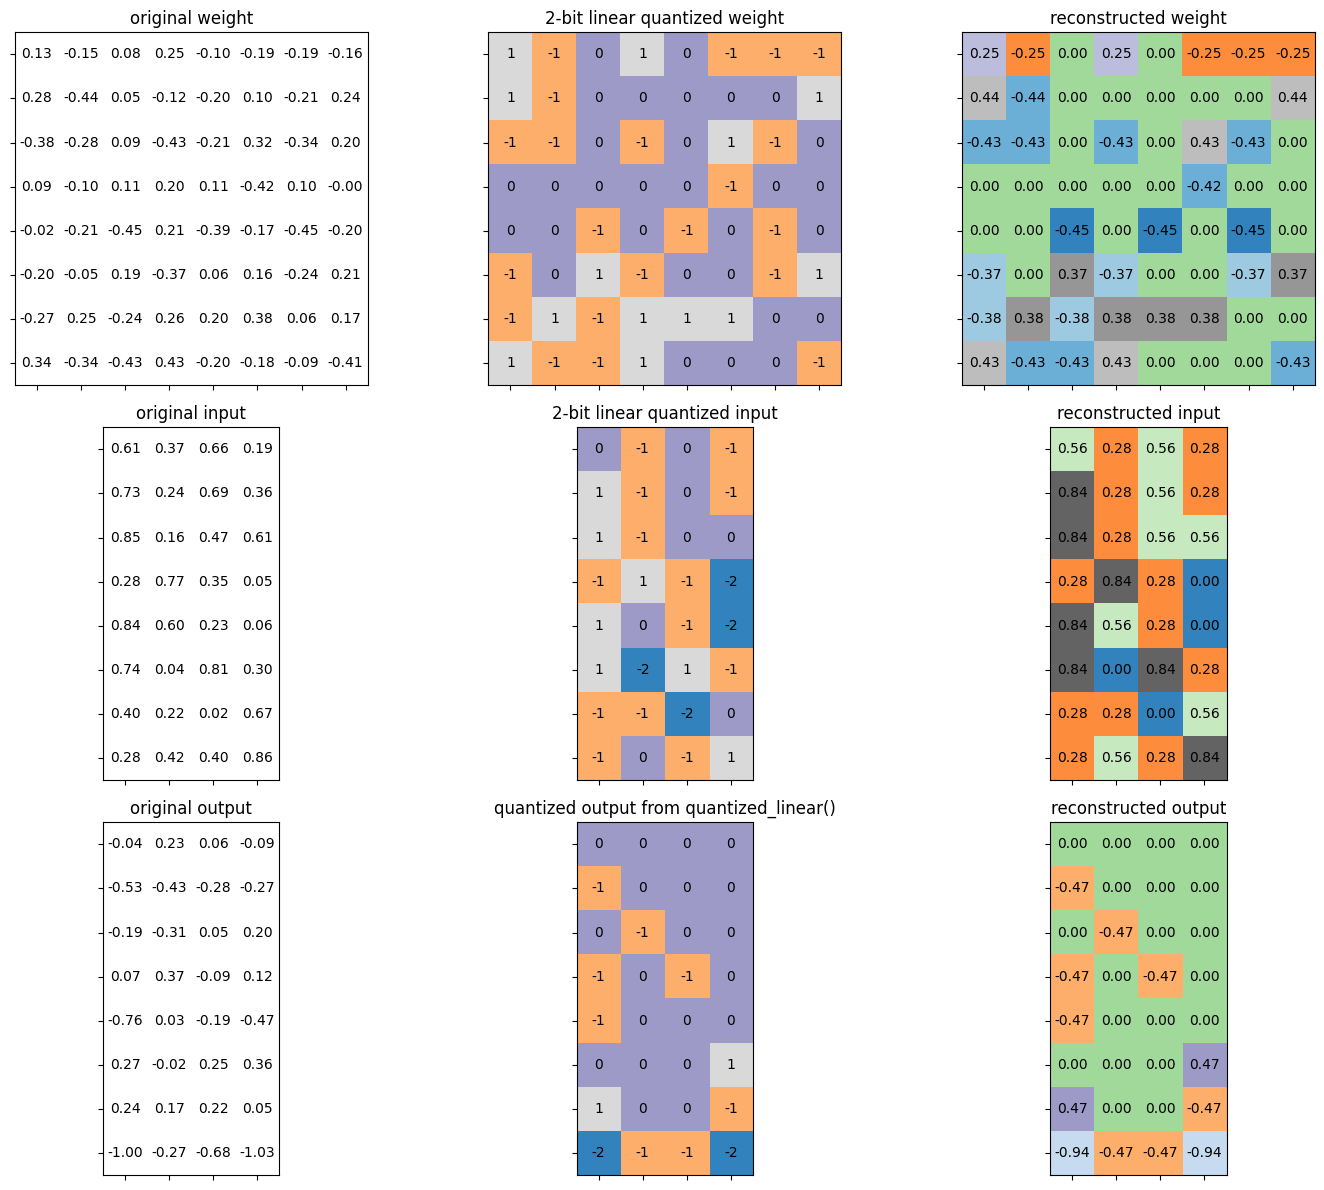

In [28]:
# 28
test_quantized_fc()

### 📘 셀 28 해설
**한 줄 요약:** 테스트를 실행합니다. `* Test passed.`가 나오면 실습 3(FC)의 구현이 정답과 일치합니다.

**그림 해석 (3행 × 3열)**

| | 왼쪽: 원본(실수) | 가운데: 2비트 정수 | 오른쪽: 실수로 복원 |
|---|---|---|---|
| 1행 | 가중치 | 양자화된 가중치 | 복원된 가중치 |
| 2행 | 입력 | 양자화된 입력 | 복원된 입력 |
| 3행 | 실수로 계산한 출력 | **정수만으로 계산한 출력** | 그 출력을 실수로 복원 |

3행의 왼쪽과 오른쪽을 비교해 보세요. 2비트(값 4가지)라서 숫자가 거칠지만 **큰 값은 크게, 작은 값은 작게** 대체로 비슷한 모습이 유지됩니다. 실제로는 8비트(256가지)를 쓰므로 훨씬 정밀합니다.

## Quantized Convolution Layer

Quantized convolution layer의 경우, 먼저 $Q_{\mathrm{bias}}$ 을 미리 계산합니다.

$Q_{\mathrm{bias}} = q_{\mathrm{bias}} - \mathrm{CONV}[Z_{\mathrm{input}}, q_{\mathrm{weight}}]$ 라는 것을 참고하세요.

In [29]:
# 29
def shift_quantized_conv2d_bias(quantized_bias, quantized_weight, input_zero_point):
    """
    shift quantized bias to incorporate input_zero_point for nn.Conv2d
        shifted_quantized_bias = quantized_bias - Conv(input_zero_point, quantized_weight)
    :param quantized_bias: [torch.IntTensor] quantized bias (torch.int32)
    :param quantized_weight: [torch.CharTensor] quantized weight (torch.int8)
    :param input_zero_point: [int] input zero point
    :return:
        [torch.IntTensor] shifted quantized bias tensor
    """
    assert(quantized_bias.dtype == torch.int32)
    assert(isinstance(input_zero_point, int))
    return quantized_bias - quantized_weight.sum((1,2,3)).to(torch.int32) * input_zero_point

### 📘 셀 29 해설
**한 줄 요약:** 셀 25의 **합성곱(Conv) 버전**입니다. 입력 zero point의 효과를 bias에 미리 반영합니다. ($Q_{bias} = q_{bias} - \mathrm{CONV}[Z_{input}, q_{weight}]$)

- `quantized_weight.sum((1,2,3))` : 가중치 모양이 (출력채널, 입력채널, 높이, 너비)이므로, **1·2·3번 차원을 모두 더하면** 출력 채널마다 "필터 안 모든 가중치의 합"이 남습니다.
- 나머지는 셀 25와 같습니다: 그 합에 `input_zero_point`를 곱해 bias에서 뺍니다.

FC 층은 가중치가 2차원이라 `sum(1)`, Conv 층은 4차원이라 `sum((1,2,3))` — 차원 수만 다르고 원리는 같습니다.

# [실습 3] Quantized convolution layer 구현

Quantized convolution layer를 추론하기 위해 다음 함수를 완성해 주세요.

**Hint**:
> $q_{\mathrm{output}} = (\mathrm{CONV}[q_{\mathrm{input}}, q_{\mathrm{weight}}] + Q_{\mathrm{bias}}) \cdot (S_{\mathrm{input}}S_{\mathrm{weight}} / S_{\mathrm{output}}) + Z_{\mathrm{output}}$


In [30]:
# 30
def quantized_conv2d(input, weight, bias, feature_bitwidth, weight_bitwidth,
                     input_zero_point, output_zero_point,
                     input_scale, weight_scale, output_scale,
                     stride, padding, dilation, groups):
    """
    quantized 2d convolution
    :param input: [torch.CharTensor] quantized input (torch.int8)
    :param weight: [torch.CharTensor] quantized weight (torch.int8)
    :param bias: [torch.IntTensor] shifted quantized bias or None (torch.int32)
    :param feature_bitwidth: [int] quantization bit width of input and output
    :param weight_bitwidth: [int] quantization bit width of weight
    :param input_zero_point: [int] input zero point
    :param samp: [int] output zero point
    :param input_scale: [float] input feature scale
    :param weight_scale: [torch.FloatTensor] weight per-channel scale
    :param output_scale: [float] output feature scale
    :return:
        [torch.(cuda.)CharTensor] quantized output feature
    """
    assert(len(padding) == 4)
    assert(input.dtype == torch.int8)
    assert(weight.dtype == input.dtype)
    assert(bias is None or bias.dtype == torch.int32)
    assert(isinstance(input_zero_point, int))
    assert(isinstance(output_zero_point, int))
    assert(isinstance(input_scale, float))
    assert(isinstance(output_scale, float))
    assert(weight_scale.dtype == torch.float)

    # Step 1: calculate integer-based 2d convolution (8-bit multiplication with 32-bit accumulation)
    input = torch.nn.functional.pad(input, padding, 'constant', input_zero_point)
    if 'cpu' in input.device.type:
        # use 32-b MAC for simplicity
        output = torch.nn.functional.conv2d(input.to(torch.int32), weight.to(torch.int32), None, stride, 0, dilation, groups)
    else:
        # 현재 버전의 PyTorch는 GPU에서 정수 기반의 conv2d() 연산을 아직 지원하지 않습니다.
        output = torch.nn.functional.conv2d(input.float(), weight.float(), None, stride, 0, dilation, groups)
        output = output.round().to(torch.int32)
    if bias is not None:
        output = output + bias.view(1, -1, 1, 1)


    # weight scale의 shape가 [oc, 1, 1, 1]인 반면, output의 shape는 [batch_size, oc, height, width]이므로 shape를 조정합니다.
    weight_scale = weight_scale.flatten().view(1, -1, 1, 1)

    # scale이 부동 소수점이므로, 출력도 부동 소수점으로 변환해야 합니다.
    output = output.float()

    ############### YOUR CODE STARTS HERE ###############
    # hint: 이번 코드 블록은 quantized_linear()와 매우 유사합니다.

    # Step 2: output 텐서를 scale합니다.
    output = output*(input_scale * weight_scale / output_scale)

    # Step 3: output을 out_zero_point 만큼 이동하여 영점을 조정합니다.
    output = output + output_zero_point
    ############### YOUR CODE ENDS HERE #################

    # 모든 값이 지정된 비트폭 범위 내에 있도록 clamp 합니다.
    output = output.round().clamp(*get_quantized_range(feature_bitwidth)).to(torch.int8)
    return output

### 📘 셀 30 해설
**한 줄 요약:** [실습 3 정답] **정수만으로 계산하는 합성곱 층**입니다. 구조는 셀 26의 `quantized_linear()`와 거의 같습니다.

**Step 1 — 정수 합성곱**
- `torch.nn.functional.pad(input, padding, 'constant', input_zero_point)` : 이미지 테두리에 값을 덧붙이는 **패딩**을 직접 수행합니다. 보통은 0을 채우지만, 양자화된 세계에서 **실수 0에 해당하는 정수는 zero point**이므로 `input_zero_point`로 채웁니다.
- `torch.nn.functional.conv2d(..., None, stride, 0, dilation, groups)` : 합성곱 계산. bias 자리는 `None`(나중에 따로 더함), 패딩은 이미 했으므로 `0`입니다.
- GPU에서는 float로 계산한 뒤 `output.round().to(torch.int32)`로 다시 정수로 바꿉니다.
- `output + bias.view(1, -1, 1, 1)` : bias(채널당 1개)를 [1, 채널수, 1, 1] 모양으로 바꿔 더하면, 브로드캐스팅으로 **각 채널의 모든 위치**에 더해집니다.

**모양 맞추기**
- `weight_scale.flatten().view(1, -1, 1, 1)` : 출력 모양 [배치, 채널수, 높이, 너비]에 맞춤

**정답 2줄** (셀 26과 동일)
- `output = output*(input_scale * weight_scale / output_scale)`
- `output = output + output_zero_point`

**마무리** : 반올림 → 범위 자르기 → `int8` 변환

> `assert(len(padding) == 4)` : 패딩은 (왼쪽, 오른쪽, 위, 아래) 4개 값으로 받아야 한다는 검사입니다.

# Quantized inference 수행

마지막으로 모든 것을 결합하여 모델에 대해 post-training int8 quantization을 수행합니다.

모델의 convolution layer과 fully-connected layer를 하나씩 quantized 버전으로 변환할 것입니다.

1. Quantization 전에 이전의 convolution layer에 BatchNorm layer을 융합(fuse)할 것입니다. 이는 quantization 전에 일반적으로 수행되는 표준 관행입니다. BatchNorm을 융합하면 추론 중에 추가적인 곱셈 연산이 줄어듭니다.


또한, 융합된 모델 `model_fused` 가 원래 모델과 동일한 정확도를 가지는지 확인할 것입니다(BatchNorm fusion은 네트워크 기능을 변경하지 않는 동등한 변환입니다).

In [31]:
# 31
def fuse_conv_bn(conv, bn):
    # modified from https://mmcv.readthedocs.io/en/latest/_modules/mmcv/cnn/utils/fuse_conv_bn.html
    assert conv.bias is None

    factor = bn.weight.data / torch.sqrt(bn.running_var.data + bn.eps)
    conv.weight.data = conv.weight.data * factor.reshape(-1, 1, 1, 1)
    conv.bias = nn.Parameter(- bn.running_mean.data * factor + bn.bias.data)

    return conv

print('Before conv-bn fusion: backbone length', len(model.backbone))
#  batchnorm 을 conv layer로 fusion 합니다.
recover_model()
model_fused = copy.deepcopy(model)
fused_backbone = []
ptr = 0
while ptr < len(model_fused.backbone):
    if isinstance(model_fused.backbone[ptr], nn.Conv2d) and \
        isinstance(model_fused.backbone[ptr + 1], nn.BatchNorm2d):
        fused_backbone.append(fuse_conv_bn(
            model_fused.backbone[ptr], model_fused.backbone[ptr+ 1]))
        ptr += 2
    else:
        fused_backbone.append(model_fused.backbone[ptr])
        ptr += 1
model_fused.backbone = nn.Sequential(*fused_backbone)

print('After conv-bn fusion: backbone length', len(model_fused.backbone))
# sanity check, no BN anymore
for m in model_fused.modules():
    assert not isinstance(m, nn.BatchNorm2d)

#  정확도는 동일해야합니다.
fused_acc = evaluate(model_fused, dataloader['test'])
print(f'Accuracy of the fused model={fused_acc:.2f}%')

Before conv-bn fusion: backbone length 29
After conv-bn fusion: backbone length 21


eval:   0%|          | 0/1 [00:00<?, ?it/s]

Accuracy of the fused model=93.00%


### 📘 셀 31 해설
**한 줄 요약:** 양자화 전 준비 단계로, **BatchNorm 층을 바로 앞 Conv 층에 합쳐서(fusion)** 없앱니다.

**왜 합칠 수 있을까?** 학습이 끝난 뒤의 BatchNorm은 "정해진 수를 곱하고 정해진 수를 더하는" 계산일 뿐입니다. Conv도 곱하고 더하는 계산이므로, 둘을 **하나의 Conv로** 합칠 수 있습니다. 결과는 완전히 같고 층 수만 줄어듭니다.

**`fuse_conv_bn(conv, bn)`**
- `factor = bn.weight.data / torch.sqrt(bn.running_var.data + bn.eps)` : BatchNorm이 곱하는 값 (채널당 1개)
- `conv.weight.data * factor.reshape(-1, 1, 1, 1)` : Conv 가중치에 그 값을 채널별로 미리 곱해 둠
- `conv.bias = nn.Parameter(- bn.running_mean.data * factor + bn.bias.data)` : BatchNorm이 더하는 값을 Conv의 bias로 넣음 (원래 Conv에는 bias가 없었음 — `assert conv.bias is None`)

**합치는 반복문**
- `model_fused = copy.deepcopy(model)` : 모델을 **통째로 복사**. 원본 `model`은 그대로 둡니다.
- `while ptr < len(model_fused.backbone):` : `ptr`(현재 위치)을 옮겨 가며 층을 하나씩 확인하는 **while 반복문**
  - 현재 층이 Conv이고 다음 층이 BatchNorm이면 → 합쳐서 리스트에 넣고 `ptr += 2` (두 칸 이동)
  - 아니면 → 그대로 넣고 `ptr += 1`
- `nn.Sequential(*fused_backbone)` : 리스트의 층들을 순서대로 이어 붙인 새 backbone. `*`는 리스트를 풀어서 인자로 넘깁니다.
- `for m in model_fused.modules(): assert not isinstance(m, nn.BatchNorm2d)` : BatchNorm이 하나도 남지 않았는지 확인

**출력 해석**
- backbone 길이 `29 → 21` : BatchNorm 8개가 사라졌습니다.
- 정확도 `93.00%` : 합치기 전과 **동일** → 기능이 바뀌지 않았음을 확인했습니다.

2. 샘플 데이터를 사용하여 모델을 실행하여 각 featuremap의 range를 얻을 것입니다. 이렇게 하면 featuremap의 range를 파악하고 해당하는 scaling factor와 zero point를 계산할 수 있습니다.

In [32]:
# 32
# add hook to record the min max value of the activation
input_activation = {}
output_activation = {}

def add_range_recoder_hook(model):
    import functools
    def _record_range(self, x, y, module_name):
        x = x[0]
        input_activation[module_name] = x.detach()
        output_activation[module_name] = y.detach()

    all_hooks = []
    for name, m in model.named_modules():
        if isinstance(m, (nn.Conv2d, nn.Linear, nn.ReLU)):
            all_hooks.append(m.register_forward_hook(
                functools.partial(_record_range, module_name=name)))
    return all_hooks

hooks = add_range_recoder_hook(model_fused)
# 훈련 데이터에서 샘플을 추출하고, 추론에 사용할 scale과 zero point를 얻습니다.
sample_data = iter(dataloader['train']).__next__()[0].cuda()
model_fused(sample_data)

# remove hooks
for h in hooks:
    h.remove()

### 📘 셀 32 해설
**한 줄 요약:** 샘플 데이터를 모델에 한 번 흘려보내면서, **각 층의 입력과 출력 값을 기록**합니다. (activation의 scale·zero point를 구하려면 값의 범위를 알아야 하기 때문)

**hook(훅)이란?** 층에 "계산이 끝날 때마다 이 함수를 불러 줘"라고 **걸어 두는 장치**입니다. 모델 코드를 고치지 않고 중간 값을 엿볼 수 있습니다.

- `input_activation = {}`, `output_activation = {}` : 기록을 담을 빈 딕셔너리(이름 → 값)
- `_record_range(self, x, y, module_name)` : 훅이 불릴 때 실행될 함수. `x`=층의 입력(튜플이라 `x[0]`으로 꺼냄), `y`=층의 출력. 층 이름을 키로 해서 저장합니다.
- `model.named_modules()` : 모델 안의 모든 층을 `(이름, 층)`으로 꺼냄
- `isinstance(m, (nn.Conv2d, nn.Linear, nn.ReLU))` : 이 세 종류 중 하나인지 검사
- `m.register_forward_hook(...)` : 그 층에 훅을 겁니다.
- `functools.partial(_record_range, module_name=name)` : 함수의 인자 중 `module_name`을 **미리 채워 넣은 새 함수**를 만듭니다. 층마다 자기 이름이 기록되게 하기 위해서입니다.

**실행 부분**
- `iter(dataloader['train']).__next__()[0].cuda()` : 학습 데이터에서 **첫 번째 묶음(512장)** 을 꺼내 이미지(`[0]`)만 GPU로 보냄
- `model_fused(sample_data)` : 모델에 통과시킴 → 이때 훅들이 값을 기록
- `for h in hooks: h.remove()` : 기록이 끝났으니 훅을 제거 (남겨 두면 이후 추론 때마다 계속 기록됨)

이렇게 대표 데이터를 흘려보내 범위를 재는 과정을 **캘리브레이션(calibration)** 이라고 합니다.

3. 마지막으로 quantization을 수행하겠습니다. 다음 매핑에 따라 모델을 변환할 것입니다.
```python
nn.Conv2d: QuantizedConv2d,
nn.Linear: QuantizedLinear,
# 아래 두 함수는 단순한 래퍼입니다.
# torch modules 은 아직 int8 데이터 포맷을 지원하지 않습니다.
# 계산을 위해 임시로 이 값을 FP32로 변환할 것입니다.
nn.MaxPool2d: QuantizedMaxPool2d,
nn.AvgPool2d: QuantizedAvgPool2d,
```

In [33]:
# 33
class QuantizedConv2d(nn.Module):
    def __init__(self, weight, bias,
                 input_zero_point, output_zero_point,
                 input_scale, weight_scale, output_scale,
                 stride, padding, dilation, groups,
                 feature_bitwidth=8, weight_bitwidth=8):
        super().__init__()
        # 현재 버전의 PyTorch는 IntTensor를 nn.Parameter로 지원하지 않습니다.
        self.register_buffer('weight', weight)
        self.register_buffer('bias', bias)

        self.input_zero_point = input_zero_point
        self.output_zero_point = output_zero_point

        self.input_scale = input_scale
        self.register_buffer('weight_scale', weight_scale)
        self.output_scale = output_scale

        self.stride = stride
        self.padding = (padding[1], padding[1], padding[0], padding[0])
        self.dilation = dilation
        self.groups = groups

        self.feature_bitwidth = feature_bitwidth
        self.weight_bitwidth = weight_bitwidth


    def forward(self, x):
        return quantized_conv2d(
            x, self.weight, self.bias,
            self.feature_bitwidth, self.weight_bitwidth,
            self.input_zero_point, self.output_zero_point,
            self.input_scale, self.weight_scale, self.output_scale,
            self.stride, self.padding, self.dilation, self.groups
            )

class QuantizedLinear(nn.Module):
    def __init__(self, weight, bias,
                 input_zero_point, output_zero_point,
                 input_scale, weight_scale, output_scale,
                 feature_bitwidth=8, weight_bitwidth=8):
        super().__init__()
        # 현재 버전의 PyTorch는 IntTensor를 nn.Parameter로 지원하지 않습니다.
        self.register_buffer('weight', weight)
        self.register_buffer('bias', bias)

        self.input_zero_point = input_zero_point
        self.output_zero_point = output_zero_point

        self.input_scale = input_scale
        self.register_buffer('weight_scale', weight_scale)
        self.output_scale = output_scale

        self.feature_bitwidth = feature_bitwidth
        self.weight_bitwidth = weight_bitwidth

    def forward(self, x):
        return quantized_linear(
            x, self.weight, self.bias,
            self.feature_bitwidth, self.weight_bitwidth,
            self.input_zero_point, self.output_zero_point,
            self.input_scale, self.weight_scale, self.output_scale
            )

class QuantizedMaxPool2d(nn.MaxPool2d):
    def forward(self, x):
        # 현재 버전의 PyTorch는 정수 기반의 MaxPool 연산을 지원하지 않습니다.
        return super().forward(x.float()).to(torch.int8)

class QuantizedAvgPool2d(nn.AvgPool2d):
    def forward(self, x):
        # 현재 버전의 PyTorch는 정수 기반의 AvgPool 연산을 지원하지 않습니다.
        return super().forward(x.float()).to(torch.int8)

feature_bitwidth = weight_bitwidth = 8
quantized_model = copy.deepcopy(model_fused)
quantized_backbone = []
ptr = 0
while ptr < len(quantized_model.backbone):
    if isinstance(quantized_model.backbone[ptr], nn.Conv2d) and \
        isinstance(quantized_model.backbone[ptr + 1], nn.ReLU):
        conv = quantized_model.backbone[ptr]
        conv_name = f'backbone.{ptr}'
        relu = quantized_model.backbone[ptr + 1]
        relu_name = f'backbone.{ptr + 1}'

        input_scale, input_zero_point = \
            get_quantization_scale_and_zero_point(
                input_activation[conv_name], feature_bitwidth)

        output_scale, output_zero_point = \
            get_quantization_scale_and_zero_point(
                output_activation[relu_name], feature_bitwidth)

        quantized_weight, weight_scale, weight_zero_point = \
            linear_quantize_weight_per_tensor(conv.weight.data, weight_bitwidth)
        quantized_bias, bias_scale, bias_zero_point = \
            linear_quantize_bias_per_output_channel(
                conv.bias.data, weight_scale, input_scale)
        shifted_quantized_bias = \
            shift_quantized_conv2d_bias(quantized_bias, quantized_weight,
                                        input_zero_point)

        quantized_conv = QuantizedConv2d(
            quantized_weight, shifted_quantized_bias,
            input_zero_point, output_zero_point,
            input_scale, weight_scale, output_scale,
            conv.stride, conv.padding, conv.dilation, conv.groups,
            feature_bitwidth=feature_bitwidth, weight_bitwidth=weight_bitwidth
        )

        quantized_backbone.append(quantized_conv)
        ptr += 2
    elif isinstance(quantized_model.backbone[ptr], nn.MaxPool2d):
        quantized_backbone.append(QuantizedMaxPool2d(
            kernel_size=quantized_model.backbone[ptr].kernel_size,
            stride=quantized_model.backbone[ptr].stride
            ))
        ptr += 1
    elif isinstance(quantized_model.backbone[ptr], nn.AvgPool2d):
        quantized_backbone.append(QuantizedAvgPool2d(
            kernel_size=quantized_model.backbone[ptr].kernel_size,
            stride=quantized_model.backbone[ptr].stride
            ))
        ptr += 1
    else:
        raise NotImplementedError(type(quantized_model.backbone[ptr]))  # should not happen
quantized_model.backbone = nn.Sequential(*quantized_backbone)

# finally, quantized the classifier
fc_name = 'classifier'
fc = model.classifier
input_scale, input_zero_point = \
    get_quantization_scale_and_zero_point(
        input_activation[fc_name], feature_bitwidth)

output_scale, output_zero_point = \
    get_quantization_scale_and_zero_point(
        output_activation[fc_name], feature_bitwidth)

quantized_weight, weight_scale, weight_zero_point = \
    linear_quantize_weight_per_tensor(fc.weight.data, weight_bitwidth)
quantized_bias, bias_scale, bias_zero_point = \
    linear_quantize_bias_per_output_channel(
        fc.bias.data, weight_scale, input_scale)
shifted_quantized_bias = \
    shift_quantized_linear_bias(quantized_bias, quantized_weight,
                                input_zero_point)

quantized_model.classifier = QuantizedLinear(
    quantized_weight, shifted_quantized_bias,
    input_zero_point, output_zero_point,
    input_scale, weight_scale, output_scale,
    feature_bitwidth=feature_bitwidth, weight_bitwidth=weight_bitwidth
)

### 📘 셀 33 해설
**한 줄 요약:** 지금까지 만든 부품을 모두 조립해, 모델의 모든 층을 **int8 양자화 버전으로 교체**합니다(가중치는 **Per-tensor**).

**① 양자화용 층 클래스 4개**
- `class QuantizedConv2d(nn.Module)` : `__init__`에서 양자화된 가중치·bias·scale·zero point 등을 저장해 두고, `forward`(층이 호출될 때 실행)에서 셀 30의 `quantized_conv2d()`를 부릅니다.
  - `super().__init__()` : 부모 클래스(`nn.Module`)의 초기화를 먼저 실행
  - `self.register_buffer('weight', weight)` : 학습되지 않는 텐서를 층에 등록. 정수 텐서는 학습용 파라미터(`nn.Parameter`)로 등록할 수 없어서 이 방법을 씁니다.
  - `self.padding = (padding[1], padding[1], padding[0], padding[0])` : (세로, 가로) 형식을 (왼쪽, 오른쪽, 위, 아래) 형식으로 변환
- `QuantizedLinear` : 같은 방식으로 셀 26의 `quantized_linear()`를 부름
- `QuantizedMaxPool2d`, `QuantizedAvgPool2d` : 기존 풀링 층을 상속해, 잠깐 float로 바꿔 계산하고 다시 `int8`로 돌려놓는 얇은 포장

**② backbone 변환 (while 반복문)**
`Conv + ReLU` 한 쌍을 만나면 다음 순서로 처리합니다.

| 순서 | 하는 일 | 사용 함수 |
|---|---|---|
| 1 | 셀 32에서 기록한 **Conv 입력**으로 입력 scale·zero point 계산 | 셀 17 |
| 2 | 기록한 **ReLU 출력**으로 출력 scale·zero point 계산 | 셀 17 |
| 3 | 가중치 양자화 | 셀 21 (Per-tensor) |
| 4 | bias 양자화 | 셀 24 |
| 5 | bias에 입력 zero point 반영 | 셀 29 |
| 6 | `QuantizedConv2d` 층 생성 후 리스트에 추가, `ptr += 2` | |

- ReLU 층은 따로 만들지 않습니다. ReLU 뒤의 값은 0 이상이므로 출력 범위의 최솟값이 0이고, 그 0이 정수 최솟값(-128)에 대응합니다. 따라서 마지막의 **범위 자르기(clamp)가 ReLU 역할**까지 해 줍니다.
- MaxPool, AvgPool은 포장 클래스로 교체하고, 그 밖의 층이 나오면 `raise NotImplementedError(...)`로 오류를 냅니다.

**③ classifier 변환** : 같은 순서로 `QuantizedLinear`를 만들어 교체합니다(bias 반영은 셀 25).

> `feature_bitwidth = weight_bitwidth = 8` : 두 변수에 한꺼번에 8을 넣습니다.

Quantization 과정이 완료되었습니다!

모델 구조를 출력하고 시각화하며, per-tensor quantized 모델의 정확도를 확인해보겠습니다.


In [34]:
# 34
print(quantized_model)

def extra_preprocess(x):
    # 원본 FP32 입력 값 범위 (0, 1)를 정수형 범위 (-128, 127)의 int8 형식으로 변환하여 입력합니다.
    return (x * 255 - 128).clamp(-128, 127).to(torch.int8)
per_tensor_int8_model_accuracy = evaluate(quantized_model, dataloader['test'],
                               extra_preprocess=[extra_preprocess])
print(f"Per-tensor quantized int8 model has accuracy={per_tensor_int8_model_accuracy:.2f}%")

VGG(
  (backbone): Sequential(
    (0): QuantizedConv2d()
    (1): QuantizedConv2d()
    (2): QuantizedMaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): QuantizedConv2d()
    (4): QuantizedConv2d()
    (5): QuantizedMaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): QuantizedConv2d()
    (7): QuantizedConv2d()
    (8): QuantizedMaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): QuantizedConv2d()
    (10): QuantizedConv2d()
    (11): QuantizedMaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): QuantizedAvgPool2d(kernel_size=2, stride=2, padding=0)
  )
  (classifier): QuantizedLinear()
)


eval:   0%|          | 0/1 [00:00<?, ?it/s]

Per-tensor quantized int8 model has accuracy=93.00%


### 📘 셀 34 해설
**한 줄 요약:** 완성된 int8 모델의 구조를 출력하고, 정확도를 측정합니다.

- `print(quantized_model)` : 모든 층이 `QuantizedConv2d`, `QuantizedMaxPool2d`, `QuantizedLinear` 등으로 바뀐 것을 확인할 수 있습니다.
- `extra_preprocess(x)` : 모델이 이제 **int8 입력**을 기대하므로, 0~1 사이 실수인 이미지를 변환합니다.
  - `x * 255 - 128` : 0 → -128, 1 → 127 로 대응
  - `.clamp(-128, 127).to(torch.int8)` : 범위 확인 후 정수형으로
- `evaluate(..., extra_preprocess=[extra_preprocess])` : 평가 함수가 모델에 넣기 직전에 이 변환을 적용합니다. 리스트로 넘기는 이유는 여러 전처리를 순서대로 적용할 수 있게 만들어져 있기 때문입니다.

**출력 해석:** `93.00%` — 가중치와 중간 값을 모두 8비트 정수로 바꿨는데도 FP32 모델과 **같은 정확도**입니다. 저장 공간은 32비트 → 8비트로 약 1/4이 됩니다.

> 이렇게 **학습이 끝난 모델을 추가 학습 없이** 양자화하는 방법을 **PTQ(Post-Training Quantization)** 라고 합니다.

이번에는 같은 과정을 per-channel로도 수행해보겠습니다.

In [35]:
# 35
class QuantizedConv2d(nn.Module):
    def __init__(self, weight, bias,
                 input_zero_point, output_zero_point,
                 input_scale, weight_scale, output_scale,
                 stride, padding, dilation, groups,
                 feature_bitwidth=8, weight_bitwidth=8):
        super().__init__()
        # 현재 버전의 PyTorch는 IntTensor를 nn.Parameter로 지원하지 않습니다.
        self.register_buffer('weight', weight)
        self.register_buffer('bias', bias)

        self.input_zero_point = input_zero_point
        self.output_zero_point = output_zero_point

        self.input_scale = input_scale
        self.register_buffer('weight_scale', weight_scale)
        self.output_scale = output_scale

        self.stride = stride
        self.padding = (padding[1], padding[1], padding[0], padding[0])
        self.dilation = dilation
        self.groups = groups

        self.feature_bitwidth = feature_bitwidth
        self.weight_bitwidth = weight_bitwidth


    def forward(self, x):
        return quantized_conv2d(
            x, self.weight, self.bias,
            self.feature_bitwidth, self.weight_bitwidth,
            self.input_zero_point, self.output_zero_point,
            self.input_scale, self.weight_scale, self.output_scale,
            self.stride, self.padding, self.dilation, self.groups
            )

class QuantizedLinear(nn.Module):
    def __init__(self, weight, bias,
                 input_zero_point, output_zero_point,
                 input_scale, weight_scale, output_scale,
                 feature_bitwidth=8, weight_bitwidth=8):
        super().__init__()
        # 현재 버전의 PyTorch는 IntTensor를 nn.Parameter로 지원하지 않습니다.
        self.register_buffer('weight', weight)
        self.register_buffer('bias', bias)

        self.input_zero_point = input_zero_point
        self.output_zero_point = output_zero_point

        self.input_scale = input_scale
        self.register_buffer('weight_scale', weight_scale)
        self.output_scale = output_scale

        self.feature_bitwidth = feature_bitwidth
        self.weight_bitwidth = weight_bitwidth

    def forward(self, x):
        return quantized_linear(
            x, self.weight, self.bias,
            self.feature_bitwidth, self.weight_bitwidth,
            self.input_zero_point, self.output_zero_point,
            self.input_scale, self.weight_scale, self.output_scale
            )

class QuantizedMaxPool2d(nn.MaxPool2d):
    def forward(self, x):
        # 현재 버전의 PyTorch는 정수 기반의 MaxPool 연산을 지원하지 않습니다.
        return super().forward(x.float()).to(torch.int8)

class QuantizedAvgPool2d(nn.AvgPool2d):
    def forward(self, x):
        # 현재 버전의 PyTorch는 정수 기반의 AvgPool 연산을 지원하지 않습니다.
        return super().forward(x.float()).to(torch.int8)

feature_bitwidth = weight_bitwidth = 8
quantized_model = copy.deepcopy(model_fused)
quantized_backbone = []
ptr = 0
while ptr < len(quantized_model.backbone):
    if isinstance(quantized_model.backbone[ptr], nn.Conv2d) and \
        isinstance(quantized_model.backbone[ptr + 1], nn.ReLU):
        conv = quantized_model.backbone[ptr]
        conv_name = f'backbone.{ptr}'
        relu = quantized_model.backbone[ptr + 1]
        relu_name = f'backbone.{ptr + 1}'

        input_scale, input_zero_point = \
            get_quantization_scale_and_zero_point(
                input_activation[conv_name], feature_bitwidth)

        output_scale, output_zero_point = \
            get_quantization_scale_and_zero_point(
                output_activation[relu_name], feature_bitwidth)

        quantized_weight, weight_scale, weight_zero_point = \
            linear_quantize_weight_per_channel(conv.weight.data, weight_bitwidth)
        quantized_bias, bias_scale, bias_zero_point = \
            linear_quantize_bias_per_output_channel(
                conv.bias.data, weight_scale, input_scale)
        shifted_quantized_bias = \
            shift_quantized_conv2d_bias(quantized_bias, quantized_weight,
                                        input_zero_point)

        quantized_conv = QuantizedConv2d(
            quantized_weight, shifted_quantized_bias,
            input_zero_point, output_zero_point,
            input_scale, weight_scale, output_scale,
            conv.stride, conv.padding, conv.dilation, conv.groups,
            feature_bitwidth=feature_bitwidth, weight_bitwidth=weight_bitwidth
        )

        quantized_backbone.append(quantized_conv)
        ptr += 2
    elif isinstance(quantized_model.backbone[ptr], nn.MaxPool2d):
        quantized_backbone.append(QuantizedMaxPool2d(
            kernel_size=quantized_model.backbone[ptr].kernel_size,
            stride=quantized_model.backbone[ptr].stride
            ))
        ptr += 1
    elif isinstance(quantized_model.backbone[ptr], nn.AvgPool2d):
        quantized_backbone.append(QuantizedAvgPool2d(
            kernel_size=quantized_model.backbone[ptr].kernel_size,
            stride=quantized_model.backbone[ptr].stride
            ))
        ptr += 1
    else:
        raise NotImplementedError(type(quantized_model.backbone[ptr]))  # should not happen
quantized_model.backbone = nn.Sequential(*quantized_backbone)

# finally, quantized the classifier
fc_name = 'classifier'
fc = model.classifier
input_scale, input_zero_point = \
    get_quantization_scale_and_zero_point(
        input_activation[fc_name], feature_bitwidth)

output_scale, output_zero_point = \
    get_quantization_scale_and_zero_point(
        output_activation[fc_name], feature_bitwidth)

quantized_weight, weight_scale, weight_zero_point = \
    linear_quantize_weight_per_channel(fc.weight.data, weight_bitwidth)
quantized_bias, bias_scale, bias_zero_point = \
    linear_quantize_bias_per_output_channel(
        fc.bias.data, weight_scale, input_scale)
shifted_quantized_bias = \
    shift_quantized_linear_bias(quantized_bias, quantized_weight,
                                input_zero_point)

quantized_model.classifier = QuantizedLinear(
    quantized_weight, shifted_quantized_bias,
    input_zero_point, output_zero_point,
    input_scale, weight_scale, output_scale,
    feature_bitwidth=feature_bitwidth, weight_bitwidth=weight_bitwidth
)

def extra_preprocess(x):
    # 원본 FP32 입력 값 범위 (0, 1)를 정수형 범위 (-128, 127)의 int8 형식으로 변환하여 입력합니다.
    return (x * 255 - 128).clamp(-128, 127).to(torch.int8)
per_channel_int8_model_accuracy = evaluate(quantized_model, dataloader['test'],
                               extra_preprocess=[extra_preprocess])

print(f"Per-tensor quantized int8 model has accuracy={per_tensor_int8_model_accuracy:.2f}%")
print(f"Per-channel quantized int8 model has accuracy={per_channel_int8_model_accuracy:.2f}%")

eval:   0%|          | 0/1 [00:00<?, ?it/s]

Per-tensor quantized int8 model has accuracy=93.00%
Per-channel quantized int8 model has accuracy=94.00%


### 📘 셀 35 해설
**한 줄 요약:** 셀 33·34와 **같은 과정을 Per-channel 방식으로** 반복합니다.

코드가 길지만 셀 33과 다른 곳은 **두 군데뿐**입니다.
```python
# 셀 33
linear_quantize_weight_per_tensor(conv.weight.data, weight_bitwidth)
linear_quantize_weight_per_tensor(fc.weight.data, weight_bitwidth)

# 셀 35
linear_quantize_weight_per_channel(conv.weight.data, weight_bitwidth)
linear_quantize_weight_per_channel(fc.weight.data, weight_bitwidth)
```
클래스 4개도 똑같은 내용으로 다시 정의되어 있습니다(다시 정의해도 문제는 없습니다). 마지막에 셀 34의 평가까지 한 번에 수행합니다.

**출력 해석:** Per-tensor `93.00%`, Per-channel `94.00%`
- Per-channel이 1%p 높게 나왔지만, 테스트 이미지가 100장뿐이라 **이미지 1장 차이**입니다. 8비트에서는 두 방식 모두 원본(93.00%) 수준을 유지한다고 이해하면 충분합니다.
- Per-channel의 장점은 4비트처럼 **비트 수가 적을 때** 더 뚜렷하게 나타납니다(셀 23의 히스토그램 참고).

# 2.2. Non-uniform Quantization

먼저 FP32(32비트 부동 소수점) 모델의 정확도와 모델 크기를 평가해봅시다.

In [36]:
# 36
fp32_model_accuracy = evaluate(model, dataloader['test'])
fp32_model_size = get_model_size(model)
print(f"fp32 model의 정확도={fp32_model_accuracy:.2f}%")
print(f"fp32 model의 크기={fp32_model_size/MiB:.2f} MiB")

eval:   0%|          | 0/1 [00:00<?, ?it/s]

fp32 model의 정확도=93.00%
fp32 model의 크기=35.20 MiB


### 📘 셀 36 해설
**한 줄 요약:** 새 섹션(Non-uniform Quantization)을 시작하기 전에 기준값을 다시 확인합니다. 셀 12와 같은 코드입니다.

앞 섹션에서 양자화한 것은 복사본(`quantized_model`)이었고 원본 `model`은 건드리지 않았으므로, 결과도 셀 12와 같습니다(정확도 `93.00%`, 크기 `35.20 MiB`).

Network quantization은 deep neural network를 표현하는 데 필요한 가중치의 bit를 줄여 network를 압축하는 방법입니다. Quantization된 network는 크기가 줄어들고, 하드웨어 지원을 통해 더 빠른 추론 속도를 가질 수 있습니다.

이번 섹션에서는 [Deep Compression: Compressing Deep Neural Networks With Pruning, Trained Quantization
And Huffman Coding](https://arxiv.org/pdf/1510.00149.pdf)에서 사용된 Non-uniform quantization 기법인 K-means quantization에 대해 살펴보겠습니다.


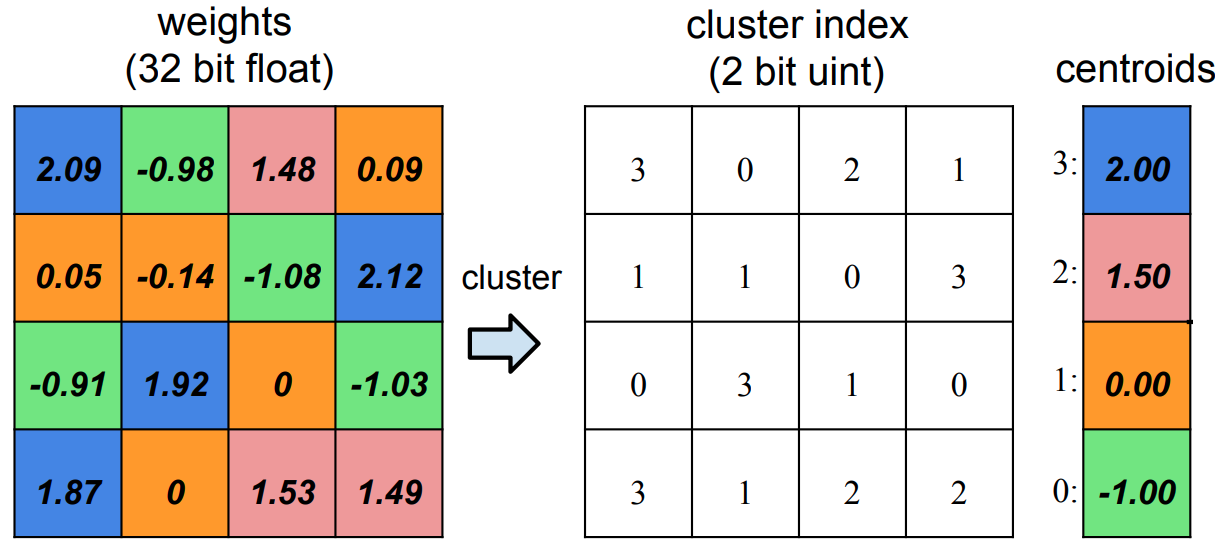


$n$-bit K-means quantization은 시냅스를 $2^n$개의 클러스터로 나누며, 동일한 클러스터에 속하는 시냅스는 동일한 가중치 값을 공유합니다.

따라서 K-means quantization은 다음을 포함하는 코드북을 생성합니다:

* centroids: $2^n$개의 FP32 클러스터들의 centroid.
* labels: 원래 FP32 가중치 텐서와 동일한 수의 요소를 가진 $n$-bit 정수 텐서. 각 정수는 해당하는 클러스터를 나타냅니다.

추론 중에, 추론용 코드북을 기반으로 fp32 텐서가 생성됩니다.

> ***quantized_weight* = *codebook.centroids*\[*codebook.labels*\].view_as(weight)**

In [37]:
# 37
from collections import namedtuple

Codebook = namedtuple('Codebook', ['centroids', 'labels'])

### 📘 셀 37 해설
**한 줄 요약:** K-means 양자화 결과를 담을 **`Codebook`이라는 묶음 자료형**을 만듭니다.

- `namedtuple('Codebook', ['centroids', 'labels'])` : **이름표가 붙은 튜플**을 만드는 도구입니다. `cb = Codebook(a, b)`로 만들고 `cb.centroids`, `cb.labels`처럼 이름으로 꺼낼 수 있습니다.

| 항목 | 내용 |
|---|---|
| `centroids` | 대표값 목록 (실수). n비트면 $2^n$개 |
| `labels` | 가중치마다 "몇 번 대표값을 쓰는지" 적은 번호표 (정수) |

원래 가중치는 `centroids[labels]`로 복원합니다. 가중치 하나당 32비트 실수 대신 **n비트짜리 번호만** 저장하면 되므로 용량이 줄어듭니다.

# [실습 4] K-means quantization 구현

다음 K-means quantization 함수를 완성해 주세요.

In [38]:
# 38
from fast_pytorch_kmeans import KMeans

dummy_tensor = torch.randn((20, 1))
kmeans = KMeans(n_clusters=4, mode='euclidean', verbose=0)
labels = kmeans.fit_predict(dummy_tensor)
centroids = kmeans.centroids

print("### Original Tensor ###")
print(dummy_tensor.view(-1))
print("### KMeans Labels ###")
print(labels)
print("### KMeans Centroids ###")
print(centroids.view(-1))

### Original Tensor ###
tensor([-0.3557, -0.3498, -2.2430,  0.0833,  0.6484,  0.0167, -2.3203,  0.3259,
        -0.0443,  1.4826, -2.8309, -1.1857, -1.2938,  1.7217, -0.7458, -0.9387,
         1.4443,  0.0091,  0.4580, -0.5566])
### KMeans Labels ###
tensor([2, 2, 0, 1, 1, 1, 0, 1, 1, 3, 0, 2, 2, 3, 2, 2, 3, 1, 1, 2])
### KMeans Centroids ###
tensor([-2.4648,  0.2139, -0.7752,  1.5495])


### 📘 셀 38 해설
**한 줄 요약:** 본격적인 구현 전에, **K-means 군집화가 무엇을 하는지** 난수 20개로 시험해 봅니다.

- `torch.randn((20, 1))` : 정규분포 난수 20개 (20행 1열)
- `KMeans(n_clusters=4, mode='euclidean', verbose=0)` : 4개 그룹으로 나누는 K-means 도구 생성 (`verbose=0`은 진행 메시지 숨김)
- `labels = kmeans.fit_predict(dummy_tensor)` : 군집화 실행 → 각 숫자가 **몇 번 그룹**인지
- `centroids = kmeans.centroids` : 각 그룹의 **중심값(평균)**

**K-means란?** 비슷한 값끼리 k개 그룹으로 묶고, 각 그룹을 그 그룹의 평균값 하나로 대표시키는 방법입니다.

**출력 해석**
- 중심값 4개: `[-2.4648, 0.2139, -0.7752, 1.5495]` (0번 ~ 3번 그룹)
- 첫 번째 숫자 `-0.3557`의 label은 `2` → 2번 그룹의 중심 `-0.7752`로 대표됩니다.
- 세 번째 숫자 `-2.2430`의 label은 `0` → `-2.4648`로 대표됩니다.

선형 양자화는 눈금 간격이 **일정**했지만, K-means는 값이 몰려 있는 곳에 대표값을 더 촘촘히 배치합니다. 그래서 **Non-uniform(비균일) 양자화**라고 부릅니다.

In [39]:
# 39
def k_means_quantize(fp32_tensor: torch.Tensor, bitwidth=4, codebook=None):
    """
    quantize tensor using k-means clustering
    :param fp32_tensor:
    :param bitwidth: [int] quantization bit width, default=4
    :param codebook: [Codebook] (the cluster centroids, the cluster label tensor)
    :return:
        [Codebook = (centroids, labels)]
            centroids: [torch.(cuda.)FloatTensor] the cluster centroids
            labels: [torch.(cuda.)LongTensor] cluster label tensor
    """
    if codebook is None:
        ############### YOUR CODE STARTS HERE ###############
        # bitwidth에 따라 클러스터 수를 설정하세요.
        n_clusters = 2**bitwidth
        ############### YOUR CODE ENDS HERE #################
        # k-means를 사용하여 quantization centroid를 얻습니다.
        kmeans = KMeans(n_clusters=n_clusters, mode='euclidean', verbose=0)
        labels = kmeans.fit_predict(fp32_tensor.view(-1, 1)).to(torch.long)
        centroids = kmeans.centroids.to(torch.float).view(-1)
        codebook = Codebook(centroids, labels)
    ############### YOUR CODE STARTS HERE ###############
    # 추론에서 사용할 quantized tensor를 구하기 위해 코드북을 디코딩하세요.
    quantized_tensor = codebook.centroids[codebook.labels]
    ############### YOUR CODE ENDS HERE #################
    fp32_tensor.set_(quantized_tensor.view_as(fp32_tensor))
    return codebook

### 📘 셀 39 해설
**한 줄 요약:** [실습 4 정답] 가중치 텐서를 **K-means로 양자화**하는 함수입니다. 코드북을 만들고, 가중치를 대표값으로 바꿔 놓습니다.

**`codebook is None`일 때 (처음 양자화할 때)**
- **(정답)** `n_clusters = 2**bitwidth` : n비트로 구분할 수 있는 그룹 수. 4비트 → 16개, 2비트 → 4개 (`**`는 거듭제곱)
- `fp32_tensor.view(-1, 1)` : 가중치를 (개수, 1) 모양으로 펴서 K-means에 넣음
- `labels = kmeans.fit_predict(...).to(torch.long)` : 가중치마다 그룹 번호
- `centroids = kmeans.centroids.to(torch.float).view(-1)` : 대표값 목록을 1줄로
- `codebook = Codebook(centroids, labels)` : 묶어서 저장

**공통 (코드북이 이미 있으면 여기부터 실행)**
- **(정답)** `quantized_tensor = codebook.centroids[codebook.labels]` : **번호표로 대표값 꺼내기**. 대괄호 안에 번호 텐서를 넣으면 번호마다 해당 값을 꺼내 줍니다.
  - 예) `centroids = [-2.46, 0.21, -0.78, 1.55]`, `labels = [2, 2, 0, 1]` → `[-0.78, -0.78, -2.46, 0.21]`
- `fp32_tensor.set_(quantized_tensor.view_as(fp32_tensor))` : 원래 모양으로 되돌려, **원본 텐서의 내용을 양자화된 값으로 교체**합니다(`_`가 붙은 제자리 수정).
- `return codebook` : 코드북을 돌려줌

> 주의: 이 방식에서 가중치의 자료형은 여전히 실수(FP32)입니다. "값의 종류가 $2^n$가지로 줄었다"는 것이 핵심이고, 실제 저장할 때 번호표(n비트)와 코드북만 저장하면 용량이 줄어듭니다.

Define misc funcions for verification.

In [40]:
# 40
def test_k_means_quantize(
    test_tensor=torch.tensor([
        [-0.3747,  0.0874,  0.3200, -0.4868,  0.4404],
        [-0.0402,  0.2322, -0.2024, -0.4986,  0.1814],
        [ 0.3102, -0.3942, -0.2030,  0.0883, -0.4741],
        [-0.1592, -0.0777, -0.3946, -0.2128,  0.2675],
        [ 0.0611, -0.1933, -0.4350,  0.2928, -0.1087]]),
    bitwidth=2):
    def plot_matrix(tensor, ax, title, cmap=ListedColormap(['white'])):
        ax.imshow(tensor.cpu().numpy(), vmin=-0.5, vmax=0.5, cmap=cmap)
        ax.set_title(title)
        ax.set_yticklabels([])
        ax.set_xticklabels([])
        for i in range(tensor.shape[1]):
            for j in range(tensor.shape[0]):
                text = ax.text(j, i, f'{tensor[i, j].item():.2f}',
                                ha="center", va="center", color="k")

    fig, axes = plt.subplots(1,2, figsize=(8, 12))
    ax_left, ax_right = axes.ravel()

    print(test_tensor)
    plot_matrix(test_tensor, ax_left, 'original tensor')

    num_unique_values_before_quantization = test_tensor.unique().numel()
    k_means_quantize(test_tensor, bitwidth=bitwidth)
    num_unique_values_after_quantization = test_tensor.unique().numel()
    print('* Test k_means_quantize()')
    print(f'    target bitwidth: {bitwidth} bits')
    print(f'        num unique values before k-means quantization: {num_unique_values_before_quantization}')
    print(f'        num unique values after  k-means quantization: {num_unique_values_after_quantization}')
    assert num_unique_values_after_quantization == min((1 << bitwidth), num_unique_values_before_quantization)
    print('* Test passed.')

    plot_matrix(test_tensor, ax_right, f'{bitwidth}-bit k-means quantized tensor', cmap='tab20c')
    fig.tight_layout()
    plt.show()

### 📘 셀 40 해설
**한 줄 요약:** `k_means_quantize()`를 5×5 예제로 검증하는 테스트 함수입니다. (정의만 하고, 실행은 다음 셀)

- `test_tensor.unique().numel()` : **서로 다른 값이 몇 종류인지** 셉니다(`unique()`는 중복 제거).
- `k_means_quantize(test_tensor, bitwidth=bitwidth)` : 2비트로 양자화 (텐서가 제자리에서 바뀜)
- `assert 양자화 후 종류 수 == min((1 << bitwidth), 양자화 전 종류 수)` : 값의 종류가 $2^n$개(2비트면 4개)로 줄었는지 검사
- 양자화 전후를 왼쪽·오른쪽 그림으로 그립니다.

정의된 K-means quantization 함수의 기능을 확인하기 위해 더미 텐서에 위의 함수를 적용해 보겠습니다.

코드는 2-bit K-means quantization을 수행하고 quantization이전과 이후의 tensor를 보여줍니다. 각 클러스터는 고유한 색상으로 표현되며, quantized tensor에는 4개의 서로 다른 색상이 표시됩니다.

정확한 함수를 작성했다면 "Test passed." 라는 문장이 출력됩니다.

tensor([[-0.3747,  0.0874,  0.3200, -0.4868,  0.4404],
        [-0.0402,  0.2322, -0.2024, -0.4986,  0.1814],
        [ 0.3102, -0.3942, -0.2030,  0.0883, -0.4741],
        [-0.1592, -0.0777, -0.3946, -0.2128,  0.2675],
        [ 0.0611, -0.1933, -0.4350,  0.2928, -0.1087]])
* Test k_means_quantize()
    target bitwidth: 2 bits
        num unique values before k-means quantization: 25
        num unique values after  k-means quantization: 4
* Test passed.


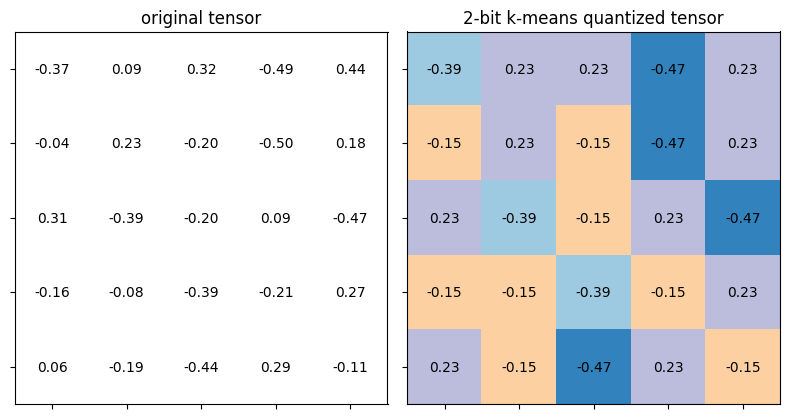

In [41]:
# 41
test_k_means_quantize()

### 📘 셀 41 해설
**한 줄 요약:** 테스트를 실행합니다. `* Test passed.`가 나오면 실습 4의 구현이 올바릅니다.

**출력 해석**
- 양자화 전 서로 다른 값: `25`개 → 양자화 후: `4`개 (2비트 = $2^2$ = 4)
- 오른쪽 그림에서 같은 그룹에 속한 칸은 **같은 색, 같은 숫자**로 표시됩니다. 비슷한 값들이 하나의 대표값으로 합쳐진 것을 볼 수 있습니다.

> K-means는 시작점을 무작위로 잡기 때문에, 실행할 때마다 대표값이 조금씩 달라질 수 있습니다.

## 전체 모델에 대한 K-means quantization

이전 실습에서 했던 것처럼, 이제 K-means quantization 함수를 전체 모델을 양자화하기 위한 클래스로 작성합니다. KMeansQuantizer 클래스에서는 코드북(즉, centroids와 labels)을 기록하여 모델 가중치가 변경될 때마다 코드북을 적용하거나 업데이트할 수 있도록 해야 합니다.

In [42]:
# 42
from torch.nn import parameter
class KMeansQuantizer:
    def __init__(self, model : nn.Module, bitwidth=4):
        self.codebook = KMeansQuantizer.quantize(model, bitwidth)

    @torch.no_grad()
    def apply(self, model, update_centroids):
        for name, param in model.named_parameters():
            if name in self.codebook:
                if update_centroids:
                    update_codebook(param, codebook=self.codebook[name])
                self.codebook[name] = k_means_quantize(
                    param, codebook=self.codebook[name])

    @staticmethod
    @torch.no_grad()
    def quantize(model: nn.Module, bitwidth=4):
        codebook = dict()
        if isinstance(bitwidth, dict):
            for name, param in model.named_parameters():
                if name in bitwidth:
                    codebook[name] = k_means_quantize(param, bitwidth=bitwidth[name])
        else:
            for name, param in model.named_parameters():
                if param.dim() > 1:
                    codebook[name] = k_means_quantize(param, bitwidth=bitwidth)
        return codebook

### 📘 셀 42 해설
**한 줄 요약:** K-means 양자화를 **모델 전체**에 적용하고, 층별 코드북을 기억해 두는 클래스입니다.

| 메서드 | 언제 | 하는 일 |
|---|---|---|
| `__init__(self, model, bitwidth=4)` | 객체를 만들 때 | `quantize`를 실행해 모델을 양자화하고, 코드북들을 `self.codebook`에 저장 |
| `quantize(model, bitwidth)` | `__init__` 안에서 | 층마다 `k_means_quantize`를 부르고 `{층이름: 코드북}` 딕셔너리를 돌려줌 |
| `apply(self, model, update_centroids)` | 학습 중 반복 호출 | 저장된 코드북으로 가중치를 **다시 양자화**. `update_centroids=True`면 그 전에 대표값을 갱신 |

- `@staticmethod` : `self`가 필요 없는 메서드. `KMeansQuantizer.quantize(...)`처럼 클래스 이름으로 부릅니다.
- `isinstance(bitwidth, dict)` : `bitwidth`가 딕셔너리이면 **층마다 다른 비트 수**를 적용하고, 숫자 하나이면 2차원 이상인 모든 가중치(`param.dim() > 1`)에 같은 비트 수를 적용합니다.
- `if name in self.codebook` : 그 층의 코드북이 있는지 확인

**`apply`가 필요한 이유:** 양자화 후 모델을 다시 학습시키면 가중치가 조금씩 변해서 "값이 $2^n$종류"라는 상태가 깨집니다. 매 학습 스텝 뒤에 `apply`를 불러 다시 대표값으로 맞춰 줍니다(셀 45에서 사용).

> `update_codebook`은 아직 정의되지 않았지만(셀 44에서 정의), 함수 안의 코드는 **실제로 호출될 때** 실행되므로 지금 오류가 나지 않습니다. 첫 줄의 `from torch.nn import parameter`는 사용되지 않는 import입니다.

이제 K-means quantization을 사용하여 모델을 8비트, 4비트 및 2비트로 quantization하겠습니다.

*코드북의 저장 공간은 모델 크기를 계산할 때 무시됩니다.*

In [43]:
# 43
fp32_model_size = get_model_size(model)
print(f"    fp32 model의 크기={fp32_model_size/MiB:.2f} MiB")
quantizers = dict()
for bitwidth in [8,4,2]:
    recover_model()
    print(f'모델을 {bitwidth} bit로 quantization 합니다.')
    quantizer = KMeansQuantizer(model, bitwidth)
    quantized_model_size = get_model_size(model, bitwidth)
    print(f"    {bitwidth}-bit k-means quantized model의 크기 : {quantized_model_size/MiB:.2f} MiB")
    quantized_model_accuracy = evaluate(model, dataloader['test'])
    print(f"    {bitwidth}-bit k-means quantized model의 정확도 : {quantized_model_accuracy:.2f}%")
    quantizers[bitwidth] = quantizer

    fp32 model의 크기=35.20 MiB
모델을 8 bit로 quantization 합니다.
    8-bit k-means quantized model의 크기 : 8.80 MiB


eval:   0%|          | 0/1 [00:00<?, ?it/s]

    8-bit k-means quantized model의 정확도 : 93.00%
모델을 4 bit로 quantization 합니다.
    4-bit k-means quantized model의 크기 : 4.40 MiB


eval:   0%|          | 0/1 [00:00<?, ?it/s]

    4-bit k-means quantized model의 정확도 : 75.00%
모델을 2 bit로 quantization 합니다.
    2-bit k-means quantized model의 크기 : 2.20 MiB


eval:   0%|          | 0/1 [00:00<?, ?it/s]

    2-bit k-means quantized model의 정확도 : 10.00%


### 📘 셀 43 해설
**한 줄 요약:** 모델을 **8비트, 4비트, 2비트**로 각각 K-means 양자화하고 크기와 정확도를 비교합니다.

반복문 한 바퀴의 흐름:
1. `recover_model()` : 원본 가중치로 복구
2. `quantizer = KMeansQuantizer(model, bitwidth)` : 만드는 순간 양자화가 수행됨
3. `get_model_size(model, bitwidth)` : 가중치 1개당 `bitwidth`비트로 계산한 크기
4. `evaluate(...)` : 정확도 측정
5. `quantizers[bitwidth] = quantizer` : 딕셔너리에 저장 (`quantizers = dict()`는 빈 딕셔너리)

**출력 해석**

| | FP32 | 8비트 | 4비트 | 2비트 |
|---|---|---|---|---|
| 크기 | 35.20 MiB | 8.80 MiB | 4.40 MiB | 2.20 MiB |
| 정확도 | 93.00% | 93.00% | 75.00% | 10.00% |

- 크기는 비트 수에 정확히 비례해 줄어듭니다(8비트 = 1/4, 2비트 = 1/16). 코드북 자체의 저장 공간은 계산에서 제외했습니다.
- 8비트(대표값 256개)는 정확도 손실이 없지만, 4비트(16개)에서 크게 떨어지고, 2비트(4개)는 **10%** — 10개 클래스 중 아무거나 찍는 수준입니다.
- 그래서 낮은 비트에서는 다음에 나오는 **재학습(QAT)** 이 필요합니다.

## Quantization-aware training(QAT)

마지막 셀의 결과에서 볼 수 있듯이, 모델을 낮은 비트로 quantization할 때 정확도가 크게 떨어집니다. 따라서 정확도를 회복하기 위해 Quantization-aware training(QAT)을 수행해야 합니다.

K-means quantization-aware training 동안, centroid도 업데이트됩니다. 이는 [Deep Compression: Compressing Deep Neural Networks With Pruning, Trained Quantization
And Huffman Coding](https://arxiv.org/pdf/1510.00149.pdf)에서 제안된 방법입니다.

centroid의 gradient는 다음과 같이 계산할 수 있습니다.

> $\frac{\partial \mathcal{L}}{\partial C_k} = \sum_{j} \frac{\partial \mathcal{L} }{\partial W_{j}} \frac{\partial W_{j} }{\partial C_k} = \sum_{j} \frac{\partial \mathcal{L} }{\partial W_{j}} \mathbf{1}(I_{j}=k)$

여기서 $\mathcal{L}$ 는 loss이며, $C_k$ 는 *k*번째 centroid, $I_{j}$는 가중치 $W_{j}$에 대한 label입니다.

$\mathbf{1}()$ 는 지시함수로, 만약 $I_{j}=k\; 이라면
\;\mathbf{1}(I_{j}=k)$ 는$\;1, 아니면\;0$이 됩니다.

&nbsp;

이번 실습에서는 단순성을 위해 다음과 같이 최신 가중치에 따라 centroid를 직접 업데이트하겠습니다:

> $C_k = \frac{\sum_{j}W_{j}\mathbf{1}(I_{j}=k)}{\sum_{j}\mathbf{1}(I_{j}=k)}$

# [실습 5] Quantization Aware Training 구현

다음 코드북 업데이트 함수를 완성해 주세요.

**Hint**:

위의 centorid 업데이트 방정식은 동일한 클러스터 내에 있는 가중치들의 평균을 사용하여 centorid 값을 새로 업데이트하는 것입니다.

In [44]:
# 44
def update_codebook(fp32_tensor: torch.Tensor, codebook: Codebook):
    """
    update the centroids in the codebook using updated fp32_tensor
    :param fp32_tensor: [torch.(cuda.)Tensor]
    :param codebook: [Codebook] (the cluster centroids, the cluster label tensor)
    """
    n_clusters = codebook.centroids.numel()
    fp32_tensor = fp32_tensor.view(-1)
    for k in range(n_clusters):
    ############### YOUR CODE STARTS HERE ###############
    # hint : torch.mean() 함수를 이용하여 평균을 구할 수 있습니다.
        codebook.centroids[k] = torch.mean(fp32_tensor[codebook.labels==k])
    ############### YOUR CODE ENDS HERE #################

### 📘 셀 44 해설
**한 줄 요약:** [실습 5 정답] 학습으로 가중치가 변한 뒤, **각 그룹의 대표값을 "현재 가중치들의 평균"으로 갱신**합니다.

- `n_clusters = codebook.centroids.numel()` : 대표값 개수
- `fp32_tensor.view(-1)` : 가중치를 1줄로 폄 (labels와 순서가 맞도록)
- `for k in range(n_clusters):` 그룹 번호를 하나씩 돌면서
  - **(정답)** `codebook.centroids[k] = torch.mean(fp32_tensor[codebook.labels==k])`
    - `codebook.labels==k` : "k번 그룹인가?"를 가중치마다 `True/False`로 표시
    - `fp32_tensor[...]` : `True`인 가중치만 골라냄 (불리언 인덱싱)
    - `torch.mean(...)` : 그 평균을 새 대표값으로 저장

위 마크다운의 수식 $C_k = \frac{\sum_j W_j \mathbf{1}(I_j=k)}{\sum_j \mathbf{1}(I_j=k)}$ ("k번 그룹 가중치의 합 ÷ k번 그룹 가중치의 개수")을 그대로 옮긴 것입니다.

**주의:** 어느 가중치가 어느 그룹인지(`labels`)는 **바꾸지 않습니다.** 그룹 구성은 그대로 두고 대표값만 움직입니다.

이제 다음 코드 셀을 실행하여 8,4,2-bit K-means quantized 모델을 fine-tune하여 정확도를 회복하겠습니다.

정확도 감소가 1%p 미만이 되면 fine-tuning을 중단합니다.

In [45]:
# 45

def train(
  model: nn.Module,
  dataloader: DataLoader,
  criterion: nn.Module,
  optimizer: Optimizer,
  scheduler: LambdaLR,
  callbacks = None
) -> None:
  model.train()

  for inputs, targets in tqdm(dataloader, desc='train', leave=False):
    # Move the data from CPU to GPU
    inputs = inputs.cuda()
    targets = targets.cuda()

    # Reset the gradients (from the last iteration)
    optimizer.zero_grad()

    # Forward inference
    outputs = model(inputs)
    loss = criterion(outputs, targets)

    # Backward propagation
    loss.backward()

    # Update optimizer and LR scheduler
    optimizer.step()
    scheduler.step()

    if callbacks is not None:
        for callback in callbacks:
            callback()

@torch.inference_mode()
def evaluate(
  model: nn.Module,
  dataloader: DataLoader,
  extra_preprocess = None
) -> float:
  model.eval()

  num_samples = 0
  num_correct = 0

  for inputs, targets in tqdm(dataloader, desc="eval", leave=False):
    # Move the data from CPU to GPU
    inputs = inputs.cuda()
    if extra_preprocess is not None:
        for preprocess in extra_preprocess:
            inputs = preprocess(inputs)

    targets = targets.cuda()

    # Inference
    outputs = model(inputs)

    # Convert logits to class indices
    outputs = outputs.argmax(dim=1)

    # Update metrics
    num_samples += targets.size(0)
    num_correct += (outputs == targets).sum()

  return (num_correct / num_samples * 100).item()

TORCH_HUB_REPO = "SKKU-ESLAB/pytorch-models"
MODEL_NAME = "cifar10_vgg9_bn" # cifar10_resnet20, cifar10_vgg11_bn

model = torch.hub.load(TORCH_HUB_REPO, MODEL_NAME, pretrained=True)
if torch.cuda.is_available():
    model = model.cuda()

accuracy_drop_threshold = 1
quantizers_before_finetune = copy.deepcopy(quantizers)
quantizers_after_finetune = quantizers

for bitwidth in [8,4,2]:
    recover_model()
    quantizer = KMeansQuantizer(model, bitwidth)
    print(f'모델을 {bitwidth} bit로 quantization 합니다.')
    quantizer.apply(model, update_centroids=False)
    quantized_model_size = get_model_size(model, bitwidth)
    print(f"    {bitwidth}-bit k-means quantized model의 크기 : {quantized_model_size/MiB:.2f} MiB")
    quantized_model_accuracy = evaluate(model, dataloader['test'])
    print(f"    {bitwidth}-bit k-means quantized model의 정확도 : {quantized_model_accuracy:.2f}% before QAT ")
    accuracy_drop = fp32_model_accuracy - quantized_model_accuracy
    if accuracy_drop > accuracy_drop_threshold:
        print(f"        정확도 감소가 {accuracy_drop:.2f}%p이므로 Quantization-aware training을 진행합니다.")
        num_finetune_epochs = 5
        optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, num_finetune_epochs)
        criterion = nn.CrossEntropyLoss()
        best_accuracy = 0
        epoch = num_finetune_epochs
        while accuracy_drop > accuracy_drop_threshold and epoch > 0:
            train(model, dataloader['train'], criterion, optimizer, scheduler,
                  callbacks=[lambda: quantizer.apply(model, update_centroids=True)])
            model_accuracy = evaluate(model, dataloader['test'])
            is_best = model_accuracy > best_accuracy
            best_accuracy = max(model_accuracy, best_accuracy)
            print(f'    Epoch {num_finetune_epochs-epoch} Accuracy {model_accuracy:.2f}% / Best Accuracy: {best_accuracy:.2f}%')
            accuracy_drop = fp32_model_accuracy - best_accuracy
            epoch -= 1
        print(f"        정확도 감소가 {accuracy_drop:.2f}%p이므로 Quantization-aware training을 종료합니다.")
    else:
        print(f"        정확도 감소가 {accuracy_drop:.2f}%p이므로 Quantization-aware training을 종료합니다.")

Using cache found in C:\Users\bioyo/.cache\torch\hub\SKKU-ESLAB_pytorch-models_main


모델을 8 bit로 quantization 합니다.
    8-bit k-means quantized model의 크기 : 8.80 MiB


eval:   0%|          | 0/1 [00:00<?, ?it/s]

    8-bit k-means quantized model의 정확도 : 92.00% before QAT 
        정확도 감소가 1.00%p이므로 Quantization-aware training을 진행합니다.


train:   0%|          | 0/98 [00:00<?, ?it/s]

eval:   0%|          | 0/1 [00:00<?, ?it/s]

    Epoch 0 Accuracy 94.00% / Best Accuracy: 94.00%
        정확도 감소가 -1.00%p이므로 Quantization-aware training을 종료합니다.
모델을 4 bit로 quantization 합니다.
    4-bit k-means quantized model의 크기 : 4.40 MiB


eval:   0%|          | 0/1 [00:00<?, ?it/s]

    4-bit k-means quantized model의 정확도 : 86.00% before QAT 
        정확도 감소가 7.00%p이므로 Quantization-aware training을 진행합니다.


train:   0%|          | 0/98 [00:00<?, ?it/s]

KeyboardInterrupt: 

### 📘 셀 45 해설
**한 줄 요약:** K-means 양자화로 떨어진 정확도를 **재학습(QAT, Quantization-Aware Training)** 으로 회복시키는 실험입니다.

**① 함수 다시 정의** : `train`(1 에폭 학습)과 `evaluate`(정확도 측정)를 정의합니다.
- `train`의 핵심 5줄: `optimizer.zero_grad()`(기울기 초기화) → `model(inputs)`(예측) → `criterion(...)`(손실 계산) → `loss.backward()`(기울기 계산) → `optimizer.step()`(가중치 수정)
- 그 뒤 `callbacks`에 담긴 함수들을 **매 스텝마다** 실행합니다.

**② 모델 준비** : `torch.hub.load(...)`로 같은 구조의 VGG 모델을 다시 불러옵니다. 이후 `recover_model()`을 부르면 이 모델에 원본 가중치가 채워집니다.

**③ 비트별 실험 (`for bitwidth in [8,4,2]`)**
1. `recover_model()` → `KMeansQuantizer(model, bitwidth)` : 원본 복구 후 양자화
2. 크기와 정확도 출력
3. `accuracy_drop = fp32_model_accuracy - quantized_model_accuracy` : 정확도 하락폭
4. 하락폭이 `accuracy_drop_threshold`(1%p)보다 크면 재학습:
   - `while accuracy_drop > accuracy_drop_threshold and epoch > 0:` : **하락폭이 1%p 이하가 되거나 5 에폭을 다 쓸 때까지** 반복
   - `callbacks=[lambda: quantizer.apply(model, update_centroids=True)]` : `lambda`는 이름 없는 한 줄 함수입니다. 매 스텝 뒤에 "대표값 갱신(셀 44) → 다시 양자화(셀 39)"를 실행해, **가중치가 항상 $2^n$종류의 값만 갖도록** 유지하면서 학습합니다.
   - `best_accuracy = max(model_accuracy, best_accuracy)` : 지금까지의 최고 정확도 기록
   - `epoch -= 1` : 남은 에폭 수 감소

**출력 해석**
- **8비트** : 양자화 직후 92.00% → 1 에폭 학습 후 94.00% → 기준 충족으로 종료
  - 하락폭이 `1.00%p`로 표시되는데도 재학습이 시작된 것은, 실수 계산의 미세한 오차로 실제 값이 1보다 아주 조금 컸기 때문으로 보입니다.
- **4비트** : 양자화 직후 86.00%, 재학습을 시작한 뒤 **`KeyboardInterrupt`로 끝났습니다.** 이는 실행 도중 사용자가 직접 중단(정지 버튼)했다는 뜻으로, 저장된 노트북에는 **4비트 재학습 결과와 2비트 결과가 남아 있지 않습니다.** 끝까지 실행하면 각 비트에 대해 에폭별 정확도가 출력됩니다.
- 4비트의 양자화 직후 정확도가 셀 43(75.00%)과 다른 것(86.00%)은 K-means의 시작점이 무작위이기 때문입니다.

> 참고: `CosineAnnealingLR(optimizer, num_finetune_epochs)`는 주기를 5로 설정했는데 `scheduler.step()`은 매 스텝(묶음)마다 불립니다. 그래서 학습률이 5 에폭에 걸쳐 서서히 줄어드는 것이 아니라 **몇 스텝 주기로 오르내립니다.** 동작에는 문제가 없지만 의도와는 다를 수 있는 부분입니다.

# 2.3. Quantization with PyTorch API

지금까지 우리는 Quantization이 실제로 어떻게 동작하는지를 알아보기 위하여 간략화 된 모듈을 직접 작성하여 실습을 진행하였습니다.

그러나 실제로 DNN 모델에 Quantization을 적용하고 배포하는 작업은 머신 러닝 라이브러리에서 제공하는 API를 이용하는 경우가 많습니다.

이번 실습에서는 Python을 위한 오픈소스 머신 러닝 라이브러리인 PyTorch에서 지원하는 Quantization API를 사용하여 다양한 Quantization 구성을 지정하고 실제로 적용해보도록 하겠습니다.

원활한 실습을 위해 지금까지 사용한 모델보다는 조금 더 작은 크기의 모델을 새로 정의하고 초기 정확도를 측정해보겠습니다.

In [ ]:
# 46
# 모델 정의
import torch.nn.functional as F
class CIFAR10Classifier(nn.Module):
    def __init__(self):
        super(CIFAR10Classifier, self).__init__()

        # 양자화 스텁 추가
        self.quant = torch.quantization.QuantStub()  # 입력을 양자화
        self.dequant = torch.quantization.DeQuantStub()  # 출력을 역양자화

        # Convolutional Layers
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

        # Fully Connected Layers
        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 10)

        # Pooling and Dropout
        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        x = self.quant(x)

        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))

        x = x.contiguous().view(-1, 128 * 4 * 4)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = F.relu(self.fc2(x))
        x = self.dropout(x)
        x = self.fc3(x)

        x = self.dequant(x)
        return x

### 📘 셀 46 해설
**한 줄 요약:** PyTorch의 양자화 기능을 실습하기 위한 **작은 CNN 모델**을 새로 정의합니다.

**`__init__` — 모델의 부품을 준비**
- `super(CIFAR10Classifier, self).__init__()` : 부모 클래스(`nn.Module`) 초기화 (`super().__init__()`과 같은 뜻)
- `self.quant = torch.quantization.QuantStub()` : **입력을 실수 → 정수로** 바꿔 줄 자리 표시
- `self.dequant = torch.quantization.DeQuantStub()` : **출력을 정수 → 실수로** 되돌릴 자리 표시
  - 지금은 아무 일도 하지 않고 통과시키기만 합니다. 나중에 양자화 변환을 하면 실제 변환 층으로 바뀝니다.
- `conv1~3` : 합성곱 층 3개 (채널 수 3 → 32 → 64 → 128)
- `fc1~3` : 완전연결 층 3개 (2048 → 256 → 128 → 10)
- `pool` : 크기를 절반으로 줄이는 MaxPool / `dropout` : 학습 중 뉴런의 50%를 무작위로 꺼서 과적합을 막는 층

**`forward` — 데이터가 흐르는 순서**
1. `x = self.quant(x)` : 양자화 시작 지점
2. `self.pool(F.relu(self.conv1(x)))` : 합성곱 → ReLU → 풀링. 이를 3번 반복하면 이미지 크기가 32 → 16 → 8 → 4가 됩니다.
3. `x.contiguous().view(-1, 128 * 4 * 4)` : (128채널, 4×4) 덩어리를 **2048개짜리 한 줄**로 폅니다. `-1`은 배치 크기를 알아서 맞추라는 뜻입니다.
4. `fc1 → ReLU → dropout → fc2 → ReLU → dropout → fc3` : 최종적으로 클래스 10개의 점수 출력
5. `x = self.dequant(x)` : 양자화 종료 지점

> `import torch.nn.functional as F` : `F.relu`처럼 층 객체를 만들지 않고 **함수 형태로** 쓰는 연산 모음입니다.

In [ ]:
# 47
!curl -L "https://github.com/SKKU-ESLAB/pytorch-models/releases/download/samsung/cifar10_model.pth" -o "D:\\data\\cifar10_model.pth"
checkpoint = torch.load('D:\\data\\cifar10_model.pth', map_location="cpu")
model = CIFAR10Classifier()
print(f"=> loading checkpoint 'cifar10_model.pth'")
model.load_state_dict(checkpoint)
recover_model = lambda : model.load_state_dict(checkpoint)

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 2551k  100 2551k    0     0  3982k      0 --:--:-- --:--:-- --:--:-- 3982k
=> loading checkpoint 'cifar10_model.pth'


### 📘 셀 47 해설
**한 줄 요약:** 이 작은 모델의 **학습된 가중치 파일을 내려받아** 모델에 넣습니다.

- `!curl -L "주소" -o "저장경로"` : 줄 맨 앞의 `!`는 파이썬이 아니라 **터미널(명령 프롬프트) 명령**을 실행하라는 주피터 문법입니다. `curl`은 파일을 내려받는 프로그램입니다.
- `torch.load('...cifar10_model.pth', map_location="cpu")` : 저장된 가중치 파일을 읽어 옵니다. `map_location="cpu"`는 CPU 메모리에 올리라는 뜻입니다.
- `model = CIFAR10Classifier()` : 셀 46의 설계도로 모델 생성(이때 가중치는 무작위 값)
- `model.load_state_dict(checkpoint)` : 읽어 온 가중치를 모델에 채워 넣음
- `recover_model = lambda : model.load_state_dict(checkpoint)` : "부르면 원본 가중치로 되돌리는" 한 줄 함수를 새로 정의

> 이번에는 `.cuda()`를 하지 않아 모델이 **CPU**에 있습니다. PyTorch의 양자화된 모델은 CPU에서 실행되기 때문입니다. 저장 경로 `D:\\data\\...`는 작성자의 PC 기준이므로, 다른 환경에서는 폴더가 있어야 합니다.

In [ ]:
# 48
# 모델 평가
original_accuracy = evaluate_model(model, testloader)
print(f"Original Model Accuracy: {original_accuracy:.2f}%")

Original Model Accuracy: 65.19%


### 📘 셀 48 해설
**한 줄 요약:** 양자화 전, 작은 모델의 **기준 정확도**를 측정합니다.

- `evaluate_model(model, testloader)` : Setup(셀 5)에서 정의한 평가 함수입니다. 앞 섹션의 `evaluate`와 달리 **테스트 데이터 10,000장 전체**를 사용합니다.

**출력 해석:** `65.19%` — VGG(93%)보다 훨씬 작고 단순한 모델이라 정확도가 낮습니다. 여기서의 목적은 높은 정확도가 아니라 "양자화 전후로 얼마나 달라지는가"를 보는 것입니다.

## Post-Training Quantization

PyTorch 라이브러리를 통해 지금까지 실습한 Post-Training Quantization을 실습해보겠습니다.

PyTorch를 통한 PTQ 적용은 다음과 같은 단계로 이루어집니다.

1. **Configuration:** Per-tensor 또는 Per-channel, Symmetric 또는 Asymmetric 등 quaitzation을 위한 구성을 담은 qconfig 설정합니다.
2. **Prepare:** prepare()함수를 통해 모델에 activation과 weight의 최소값 및 최대값 관찰하기 위한 observer를 삽입합니다.
3. **Calibration:** 데이터세트의 일부를 사용하여 추론을 진행하면서, observer가 각 activation과 weight의 최소값 및 최대값 관찰하여 기록합니다.
4. **Convert:** convert()함수를 통해 observer가 관찰한 최소값 및 최대값을 반영하여 모델에 실제 quantization을 적용합니다.

### Configuration

PyTorch에서 Quantization을 적용하기 위해서는 먼저 qconfig을 통해 Quantization의 구성을 지정해주어야 합니다.

qconfig은 weight 및 activation에 대한 quantization scheme, datatype, range를 결정하는 과정에서 사용되는 observer 등의 정보를 담고있습니다.

먼저 PyTorch에서 Quantization에서 기본적으로 사용되는 default_qconfig의 구성을 알아보겠습니다.

In [ ]:
# 49
# default_qconfig 로드
default_qconfig = torch.quantization.default_qconfig
qconfig_printer(default_qconfig)

Weight Observer: MinMaxObserver
Weight dtype: torch.qint8
Weight qscheme: torch.per_tensor_symmetric
Weight quant_min: -128
Weight quant_max: 127
----------------------------------------------
Activation Observer: MinMaxObserver
Activation dtype: torch.quint8
Activation qscheme: torch.per_tensor_affine
Activation quant_min: 0
Activation quant_max: 127


### 📘 셀 49 해설
**한 줄 요약:** PyTorch가 제공하는 **기본 양자화 설정(`default_qconfig`)** 의 내용을 출력해 봅니다.

- **qconfig** : "가중치는 어떻게, activation은 어떻게 양자화할지"를 적어 둔 설정 묶음
- `qconfig_printer(...)` : Setup(셀 11)에서 만든 출력용 함수

**출력 해석**

| 항목 | Weight (가중치) | Activation (층의 출력) |
|---|---|---|
| Observer | MinMaxObserver | MinMaxObserver |
| dtype | `qint8` (부호 있는 8비트) | `quint8` (부호 없는 8비트) |
| qscheme | `per_tensor_symmetric` | `per_tensor_affine` |
| 범위 | -128 ~ 127 | 0 ~ 127 |

- **Observer(관찰자)** : 값이 지나갈 때 최솟값·최댓값을 기록하는 도구. 셀 32에서 hook으로 직접 했던 일을 대신해 줍니다.
- **symmetric(대칭)** : zero point = 0 (셀 20의 방식) / **affine(비대칭)** : zero point 사용 (셀 17의 방식)
- **per_tensor** : 텐서 전체에 scale 하나 (셀 21의 방식)

즉 앞에서 **직접 구현한 방식들이 PyTorch 안에 그대로 들어 있습니다.** activation의 최댓값이 255가 아닌 127인 것은, 일부 CPU에서 계산 중 넘침(overflow)을 피하려고 범위를 1비트 줄여 쓰는 기본 설정 때문입니다.

PyTorch에서 Quantization에서 기본적으로 사용되는 deafult_qconfig의 구성에서는 weight에서는 Per-tensor symmetric quantization을, activation에서는 Per-tensor asymmetric quantization을 사용하여 진행하는 것을 알 수 있습니다.

PyTorch는 다음과 같은 scheme과 datatype을 지원하고 있습니다.

#### QScheme (`torch.qscheme`): a enum that specifies the way we quantize the Tensor
- `torch.per_tensor_affine`
- `torch.per_tensor_symmetric`
- `torch.per_channel_affine`
- `torch.per_channel_symmetric`

#### dtype (`torch.dtype`): data type of the quantized Tensor
- `torch.quint8`
- `torch.qint8`
- `torch.qint32`
- `torch.float16`

### Prepare

Quantization을 위해서는 각 텐서의 값 분포를 파악하는 것이 중요합니다. 이 분포를 파악하기 위해, observer라는 특수한 모듈을 모델의 레이어에 추가합니다.
관찰자는 실행 중인 모델의 데이터를 모니터링하여 최소값과 최대값을 포함한 통계를 수집합니다. 이 정보는 나중에 데이터의 범위를 적절하게 측정하여 quatization range를 설정하기 위하여 사용됩니다.

Prepare 단계에서는 prepare()함수를 통해 모델에 activation과 weight의 최소값 및 최대값 관찰하기 위한 observer를 삽입합니다.

PyTorch는 다음과 같은 observer들을 지원하고 있습니다.

#### torch.ao.quantization.observer

- MinMaxObserver

- MovingAverageMinMaxObserver

- PerChannelMinMaxObserver

- MovingAveragePerChannelMinMaxObserver

- HistogramObserver

모델에 default qconfig과 prepare()를 적용해보고 모델 내부 모듈의 변화를 살펴보겠습니다.

In [ ]:
# 50
model.qconfig = default_qconfig
print(model)
prepared_model = torch.quantization.prepare(model, inplace=False)
print("--------------------------------------------------------------------------------------------")
print(prepared_model)

CIFAR10Classifier(
  (quant): QuantStub()
  (dequant): DeQuantStub()
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=2048, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.5, inplace=False)
)
--------------------------------------------------------------------------------------------
CIFAR10Classifier(
  (quant): QuantStub(
    (activation_post_process): MinMaxObserver(min_val=inf, max_val=-inf)
  )
  (dequant): DeQuantStub()
  (conv1): Conv2d(
    3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)
    (activation_post_process): MinMaxObserver(min_val=inf, max_val

/tmp/ipykernel_527/3261976887.py:3: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  prepared_model = torch.quantization.prepare(model, inplace=False)


### 📘 셀 50 해설
**한 줄 요약:** [PTQ 2단계: Prepare] 모델에 설정을 지정하고, **observer(관찰자)를 각 층에 끼워 넣습니다.**

- `model.qconfig = default_qconfig` : 모델에 "이 설정으로 양자화할 것"이라고 표시
- `torch.quantization.prepare(model, inplace=False)` : observer가 삽입된 모델을 만듭니다. `inplace=False`이므로 원본 `model`은 그대로 두고 **복사본**을 돌려줍니다.

**출력 해석** (구분선 위 = 원본, 아래 = prepare 후)
- 각 층 안에 `(activation_post_process): MinMaxObserver(min_val=inf, max_val=-inf)`가 추가되었습니다.
- `min_val=inf, max_val=-inf`는 **아직 아무 값도 관찰하지 않은 초기 상태**입니다. (최솟값을 찾기 위해 무한대에서, 최댓값을 찾기 위해 음의 무한대에서 시작)

모듈 내부에 qconfig을 통해 설정 된 MinMaxobserver가 삽입된 모습을 볼 수 있습니다.

### Calibration

quantization 과정에서의 calibration 단계는 quantization된 모델이 원본 모델의 정확도를 유지할 수 있도록 observer를 사용하여 입력 데이터의 분포를 측정하는 과정입니다.

calibration 과정에서는 모델에 데이터세트의 일부를 전달하여 실행합니다. 이 데이터는 일반적으로 validation 데이터세트나 train 데이터세트에서 추출합니다.

observer는 이 데이터를 사용하여 각 레이어의 활성화와 가중치의 최소값 및 최대값을 측정합니다.

calibration을 통해 observer가 min값과 max값을 제대로 측정하였는지 관찰해보겠습니다.

In [ ]:
# 51
from copy import deepcopy

print(prepared_model)
calibrated_model = deepcopy(prepared_model)
# Calibration 수행 (첫 번째 배치로 모델에 입력 전달)
for images, _ in trainloader:
    calibrated_model(images)
    break  # Calibration을 한 번만 수행
print("--------------------------------------------------------------------------------------------")
print(calibrated_model)

CIFAR10Classifier(
  (quant): QuantStub(
    (activation_post_process): MinMaxObserver(min_val=inf, max_val=-inf)
  )
  (dequant): DeQuantStub()
  (conv1): Conv2d(
    3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)
    (activation_post_process): MinMaxObserver(min_val=inf, max_val=-inf)
  )
  (conv2): Conv2d(
    32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)
    (activation_post_process): MinMaxObserver(min_val=inf, max_val=-inf)
  )
  (conv3): Conv2d(
    64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)
    (activation_post_process): MinMaxObserver(min_val=inf, max_val=-inf)
  )
  (fc1): Linear(
    in_features=2048, out_features=256, bias=True
    (activation_post_process): MinMaxObserver(min_val=inf, max_val=-inf)
  )
  (fc2): Linear(
    in_features=256, out_features=128, bias=True
    (activation_post_process): MinMaxObserver(min_val=inf, max_val=-inf)
  )
  (fc3): Linear(
    in_features=128, out_features=10, bias=True
    (activation_post_process)

### 📘 셀 51 해설
**한 줄 요약:** [PTQ 3단계: Calibration] 실제 데이터를 한 묶음 통과시켜, observer가 **값의 범위를 기록**하게 합니다.

- `calibrated_model = deepcopy(prepared_model)` : 통째로 복사(prepare 직후 상태를 보존하기 위해)
- `for images, _ in trainloader:` : 데이터를 묶음 단위로 꺼냄. 정답(label)은 필요 없으므로 `_`로 받아 버립니다.
- `calibrated_model(images)` : 모델에 통과시킴 → 지나가는 값을 observer들이 관찰
- `break` : 반복문을 **즉시 빠져나옴** → 첫 번째 묶음(1,024장)만 사용

**출력 해석** (구분선 아래)
- `min_val`, `max_val`이 `inf`에서 실제 숫자로 바뀌었습니다. 예) 입력(`quant`): 약 -2.43 ~ 2.75
- `dequant`에 붙은 것 하나만 `inf`로 남아 있는데, 그 층은 관찰이 필요 없어 쓰이지 않기 때문입니다.

이 숫자들로 다음 단계에서 각 층의 scale과 zero point가 계산됩니다(셀 17의 공식과 같은 원리).

Observer 모듈 내부의 min_val과 max_val이 초기값인 -inf,inf에서 적절한 값으로 변경된 것을 확인할 수 있습니다.

### Convert
convert단계에서는 convert()함수를 통해 캘리브레이션 단계에서 수집된 정보를 사용하여 각 weight를 정수로 양자화합니다.

이 과정에서 계산된 scale과 zero point가 적용되어 실제 weight 값이 정수형 텐서로 변환됩니다.

또한 원래 모델의 표준 레이어(예: nn.Conv2d, nn.Linear 등)는 그에 상응하는 quantized 버전(예: nn.quantized.Conv2d, nn.quantized.Linear 등)으로 교체됩니다.

이 교체는 모델이 효율적으로 실행될 수 있도록 하드웨어 가속을 활용하는 함수가 될 수 있습니다.

Convert()를 통해 모델이 실제로 quantized 모듈로 변경되는지 관찰해보고, 실제 quantized 된 모델을 통해 추론을 진행해보겠습니다.

In [ ]:
# 52
quantized_model = torch.quantization.convert(
    calibrated_model, inplace=False
)

print(quantized_model)
print("\n")
quantized_accuracy = evaluate_model(quantized_model, testloader)

print(f"Original model has accuracy={original_accuracy:.2f}%")
print(f"PTQ quantized model has accuracy={quantized_accuracy:.2f}%")

CIFAR10Classifier(
  (quant): Quantize(scale=tensor([0.0408]), zero_point=tensor([60]), dtype=torch.quint8)
  (dequant): DeQuantize()
  (conv1): QuantizedConv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), scale=0.12335377931594849, zero_point=64, padding=(1, 1))
  (conv2): QuantizedConv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), scale=0.15371008217334747, zero_point=50, padding=(1, 1))
  (conv3): QuantizedConv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), scale=0.14764930307865143, zero_point=67, padding=(1, 1))
  (fc1): QuantizedLinear(in_features=2048, out_features=256, scale=0.0814727321267128, zero_point=69, qscheme=torch.per_tensor_affine)
  (fc2): QuantizedLinear(in_features=256, out_features=128, scale=0.06293904036283493, zero_point=43, qscheme=torch.per_tensor_affine)
  (fc3): QuantizedLinear(in_features=128, out_features=10, scale=0.21691980957984924, zero_point=54, qscheme=torch.per_tensor_affine)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=

/tmp/ipykernel_527/471336938.py:1: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  quantized_model = torch.quantization.convert(


Original model has accuracy=65.19%
PTQ quantized model has accuracy=65.05%


### 📘 셀 52 해설
**한 줄 요약:** [PTQ 4단계: Convert] 관찰한 범위를 이용해 **모델을 실제 양자화 모델로 변환**하고 정확도를 잽니다.

- `torch.quantization.convert(calibrated_model, inplace=False)` : observer를 제거하고, 각 층을 양자화 버전으로 교체한 모델을 돌려줍니다.
- `evaluate_model(quantized_model, testloader)` : 테스트 10,000장으로 정확도 측정

**출력 해석**
- 층 이름이 `Conv2d` → `QuantizedConv2d`, `Linear` → `QuantizedLinear`로 바뀌었고, 각 층에 **`scale=..., zero_point=...`** 가 표시됩니다. 앞에서 손으로 계산했던 바로 그 값들입니다.
- `quant`도 `Quantize(scale=0.0408, zero_point=60, ...)`로 바뀌었습니다. 입력을 받아 실제로 정수로 바꾸는 층이 된 것입니다.
- 정확도: 원본 `65.19%` → PTQ `65.05%`. **0.14%p**만 떨어졌습니다.
- 중간의 `DeprecationWarning`은 "이 API는 앞으로 없어질 예정"이라는 **경고**일 뿐 오류가 아닙니다. 결과에는 영향이 없습니다.

**PTQ 4단계 정리:** 설정(qconfig) → 준비(prepare, observer 삽입) → 보정(calibration, 데이터 통과) → 변환(convert)

지금까지 PTQ기법을 통해서 PyTorch를 통해 실제로 Quantization을 진행하고 Original model과 정확도를 비교해보았습니다.

그러나 PTQ는 학습이 완료된 모델에 대해 quantization을 적용합니다. 이 과정에서 모델이 데이터의 모든 특성을 포괄적으로 학습하지 않은 상태에서 quantization을 수행하며, 또한 activation의 출력값 분포가 동적인 경우, calibration에서 얻은 scaling factor와 zero point가 모든 입력 상황에 적합하지 않을 수 있습니다. 이러한 경우 원본 모델보다 정확도 손실이 발생 할 수 있습니다.

이러한 손실을 줄이기 위해, 모델 학습 과정에서 Quantization을 시뮬레이션하고 정확도 저하를 최소화하는 방향으로 학습하는 방식인 QAT(Quantization-Aware Trainging) 이 등장하였습니다.

# Quantization-Aware Training

Quantization-Aware Training 모델의 quantization을 고려하여 이를 학습 과정에 포함시키는 방식입니다.

QAT의 목적은 훈련 단계에서부터 모델이 quantization에 따른 정보 손실을 경험하게 함으로써, 실제 quantization이 적용된 모델도 성능 저하 없이 배포될 수 있도록 하는 것입니다.

PyTorch의 Quantization API는 PTQ 뿐만 아니라 QAT 역시 지원합니다.

PyTorch를 통한 QAT 적용은 다음과 같은 단계로 이루어집니다.

## 1.Configuration
- Per-tensor 또는 Per-channel, Symmetric 또는 Asymmetric 등 quaitzation을 위한 구성을 담은 qconfig 설정합니다.
## 2.Prepare
- prepare()함수를 통해 모델에서 학습 중 quantization을 모방하여 quantization error를 시뮬레이션하는 fake quantizer를 삽입합니다.
## 3.Training
- 학습 데이터세트를 사용하여 학습을 진행하면서, fake quantizer가 quantization error를 시뮬레이션하여 loss에 반영합니다. PTQ와 다르게, QAT는 모델의 scaling factor와 zero point뿐만 아니라 모델의 weight 또한 학습합니다.
## 4.Convert
- convert()함수를 통해 fake quantizer가 학습한 scaling factor와 zero point를 반영하여 모델에 실제 quantization을 적용합니다.

### Configuration

PyTorch에서 QAT를 적용하기 위해서는 먼저 qconfig을 통해 Quantization의 구성을 지정해주어야 합니다.

PTQ와 마찬가지로, qconfig은 weight 및 activation에 대한 quantization scheme, datatype 뿐만 아니라 observer 대신 fake quantizer에 대한 정보도 담고있습니다.

먼저 PyTorch에서 Quantization에서 기본적으로 사용되는 deafult_qconfig의 구성을 알아보겠습니다.

In [ ]:
# 53
# default_qconfig 로드
default_qat_qconfig = torch.quantization.default_qat_qconfig
qconfig_printer(default_qat_qconfig)

Weight Observer: FakeQuantize
Weight dtype: torch.qint8
Weight qscheme: torch.per_tensor_symmetric
Weight quant_min: -128
Weight quant_max: 127
----------------------------------------------
Activation Observer: FakeQuantize
Activation dtype: torch.quint8
Activation qscheme: torch.per_tensor_affine
Activation quant_min: 0
Activation quant_max: 127


/usr/local/lib/python3.12/dist-packages/torch/ao/quantization/observer.py:534: UserWarning: Please use quant_min and quant_max to specify the range for observers.                     reduce_range will be deprecated in a future release of PyTorch.
  super().__init__(


### 📘 셀 53 해설
**한 줄 요약:** 이번에는 **QAT용 기본 설정(`default_qat_qconfig`)** 을 출력해 봅니다.

**출력 해석:** dtype, qscheme, 범위는 셀 49와 같고, Observer 자리만 `MinMaxObserver` → **`FakeQuantize`** 로 바뀌었습니다.

**FakeQuantize(가짜 양자화)란?** 값을 "양자화했다가 바로 실수로 복원"해서 내보내는 층입니다. 자료형은 실수 그대로이지만 **양자화 오차가 섞인 값**이 되므로, 모델이 학습하는 동안 "양자화되면 이런 오차가 생긴다"는 것을 미리 경험하게 됩니다. 범위를 관찰하는 observer 기능도 함께 갖고 있습니다.

> `UserWarning`은 설정 방식에 대한 경고일 뿐 실행에는 문제가 없습니다.

### Prepare

QAT를 위해서는 학습 중 quantization을 모방하여 quantization error를 계산하고 scale과 zero-point를 산출해내기 위한 fake quantizer가 필요합니다.

이를 위해 fake quantizer라는 모듈을 추가하여 모델 학습 중 quantization error를 수집합니다.

Prepare 단계에서는 prepare()함수를 통해 모델에 fake quantizer를 삽입합니다.

모델에 default qconfig과 prepare()를 적용해보고 모델 내부 모듈의 변화를 살펴보겠습니다.

In [ ]:
# 54
model.qconfig = default_qat_qconfig
print(model)
prepared_qat_model = torch.quantization.prepare(model, inplace=False)
print("--------------------------------------------------------------------------------------------")
print(prepared_qat_model)

CIFAR10Classifier(
  (quant): QuantStub()
  (dequant): DeQuantStub()
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=2048, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.5, inplace=False)
)
--------------------------------------------------------------------------------------------
CIFAR10Classifier(
  (quant): QuantStub(
    (activation_post_process): FakeQuantize(
      fake_quant_enabled=tensor([1], dtype=torch.uint8), observer_enabled=tensor([1], dtype=torch.uint8), quant_min=0, quant_max=127, dtype=torch.quint8, qscheme=torch.per_tensor_affine, ch_axis=-1, scale=

/tmp/ipykernel_527/3293036665.py:3: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  prepared_qat_model = torch.quantization.prepare(model, inplace=False)


### 📘 셀 54 해설
**한 줄 요약:** [QAT 2단계: Prepare] QAT 설정으로 `prepare()`를 실행해, 각 층에 **FakeQuantize를 끼워 넣습니다.**

코드는 셀 50과 같고 설정만 `default_qat_qconfig`로 바뀌었습니다.

**출력 해석** (구분선 아래)
- 각 층 안에 `(activation_post_process): FakeQuantize(...)`가 들어 있고, 그 안에 다시 `MovingAverageMinMaxObserver`가 있습니다.
- `scale=tensor([1.]), zero_point=tensor([0])`은 초기값입니다. 학습하면서 갱신됩니다.
- `MovingAverageMinMaxObserver` : 최솟값·최댓값을 한 번에 확정하지 않고, 새 데이터가 올 때마다 **조금씩 반영해 가는(이동 평균)** 관찰자입니다. 학습 중에는 값의 범위가 계속 변하기 때문입니다.

> 참고: 출력을 보면 층 자체는 여전히 보통의 `Conv2d`, `Linear`입니다. 즉 이 방법(`prepare()`)으로는 **층의 출력(activation)** 에만 가짜 양자화가 적용됩니다. 가중치에도 가짜 양자화를 적용하려면 PyTorch에서는 보통 `prepare_qat()`를 사용합니다.

모듈 내부에 qconfig을 통해 설정 된 fakequantizer가 삽입된 모습을 볼 수 있습니다.

### Training

QAT는 PTQ와 달리, calibration 단계가 아닌 training을 통해 quantization을 시뮬레이션하고 quantization error를 반영한 scale factor와 zero point를 찾고 모델의 weight또한 fine-tuning 하게 됩니다.

calibration 과정에서는 모델에 데이터세트의 일부를 전달하여 실행합니다. 이 데이터는 일반적으로 validation 데이터세트나 train 데이터세트에서 추출합니다.

observer는 이 데이터를 사용하여 각 레이어의 활성화와 가중치의 최소값 및 최대값을 측정합니다.

QAT를 위해 5epoch 동안 training을 진행한 뒤, fake quantizer가 min값과 max값을 제대로 측정하였는지 관찰해보겠습니다.

In [ ]:
# 55
from copy import deepcopy

print(prepared_qat_model)
trained_qat_model = deepcopy(prepared_qat_model)
trained_qat_model.qconfig = torch.quantization.default_qat_qconfig

trained_qat_model = train_model(trained_qat_model, trainloader, epochs=5)
print("--------------------------------------------------------------------------------------------")
print(trained_qat_model)

CIFAR10Classifier(
  (quant): QuantStub(
    (activation_post_process): FakeQuantize(
      fake_quant_enabled=tensor([1], dtype=torch.uint8), observer_enabled=tensor([1], dtype=torch.uint8), quant_min=0, quant_max=127, dtype=torch.quint8, qscheme=torch.per_tensor_affine, ch_axis=-1, scale=tensor([1.]), zero_point=tensor([0], dtype=torch.int32)
      (activation_post_process): MovingAverageMinMaxObserver(min_val=inf, max_val=-inf)
    )
  )
  (dequant): DeQuantStub()
  (conv1): Conv2d(
    3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)
    (activation_post_process): FakeQuantize(
      fake_quant_enabled=tensor([1], dtype=torch.uint8), observer_enabled=tensor([1], dtype=torch.uint8), quant_min=0, quant_max=127, dtype=torch.quint8, qscheme=torch.per_tensor_affine, ch_axis=-1, scale=tensor([1.]), zero_point=tensor([0], dtype=torch.int32)
      (activation_post_process): MovingAverageMinMaxObserver(min_val=inf, max_val=-inf)
    )
  )
  (conv2): Conv2d(
    32, 64, kernel_size=(

### 📘 셀 55 해설
**한 줄 요약:** [QAT 3단계: Training] FakeQuantize가 들어간 모델을 **5 에폭 동안 학습**시킵니다.

- `deepcopy(prepared_qat_model)` : 복사본을 만들어 학습 (prepare 직후 상태 보존)
- `train_model(trained_qat_model, trainloader, epochs=5)` : Setup(셀 5)에서 정의한 학습 함수. 에폭마다 평균 손실(Loss)을 출력합니다.

**PTQ와의 차이**
- PTQ : 데이터를 **통과만** 시켜 범위를 관찰 (가중치는 그대로)
- QAT : 양자화 오차가 섞인 상태로 **실제 학습** → 가중치가 양자화에 잘 견디는 방향으로 조정됨

**출력 해석**
- 손실: `1.0611 → 1.0324 → 1.0104 → 0.9936 → 0.9636` 으로 계속 줄어듭니다(학습이 진행되고 있다는 뜻).
- 구분선 아래 모델에서 observer의 `min_val`, `max_val`이 실제 값으로 채워졌습니다. 셀 51의 값과 조금 다른 것은 학습으로 가중치가 변했고, 여러 묶음에 걸쳐 관찰했기 때문입니다.

### Convert
마지막으로 convert단계에서는 PTQ와 마찬가지로 convert()함수를 통해 training 단계에서 수집된 정보를 사용하여 각 weight를 정수로 양자화합니다.

이 과정에서 계산된 scale과 zero point가 적용되어 실제 weight 값이 정수형 텐서로 변환됩니다.

또한 원래 모델의 표준 레이어(예: nn.Conv2d, nn.Linear 등)는 그에 상응하는 quantized 버전(예: nn.quantized.Conv2d, nn.quantized.Linear 등)으로 교체됩니다.

이 교체는 모델이 효율적으로 실행될 수 있도록 하드웨어 가속을 활용하는 함수가 될 수 있습니다.

Convert()를 통해 모델이 실제로 quantized 모듈로 변경되는지 관찰해보고, 실제 QAT를 통해 quantized 된 모델을 통해 추론을 진행해보겠습니다.

In [ ]:
# 56
qat_quantized_model = torch.quantization.convert(
    trained_qat_model, inplace=False
)

print(qat_quantized_model)
print("\n")
qat_quantized_accuracy = evaluate_model(qat_quantized_model, testloader)

print(f"Original model has accuracy={original_accuracy:.2f}%")
print(f"QAT quantized model has accuracy={qat_quantized_accuracy:.2f}%")

CIFAR10Classifier(
  (quant): Quantize(scale=tensor([0.0408]), zero_point=tensor([60]), dtype=torch.quint8)
  (dequant): DeQuantize()
  (conv1): QuantizedConv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), scale=0.12938126921653748, zero_point=62, padding=(1, 1))
  (conv2): QuantizedConv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), scale=0.1724090278148651, zero_point=45, padding=(1, 1))
  (conv3): QuantizedConv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), scale=0.17821113765239716, zero_point=70, padding=(1, 1))
  (fc1): QuantizedLinear(in_features=2048, out_features=256, scale=0.09022499620914459, zero_point=75, qscheme=torch.per_tensor_affine)
  (fc2): QuantizedLinear(in_features=256, out_features=128, scale=0.07720161974430084, zero_point=48, qscheme=torch.per_tensor_affine)
  (fc3): QuantizedLinear(in_features=128, out_features=10, scale=0.26965415477752686, zero_point=54, qscheme=torch.per_tensor_affine)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=

/tmp/ipykernel_527/832983983.py:1: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  qat_quantized_model = torch.quantization.convert(


Original model has accuracy=65.19%
QAT quantized model has accuracy=68.21%


### 📘 셀 56 해설
**한 줄 요약:** [QAT 4단계: Convert] 학습을 마친 모델을 **실제 양자화 모델로 변환**하고 정확도를 잽니다. 코드는 셀 52와 같습니다.

**출력 해석**
- 구조는 셀 52와 같은 양자화 모델이고, 각 층의 `scale`, `zero_point` 값이 조금 다릅니다(학습으로 범위가 달라졌기 때문).
- 정확도: 원본 `65.19%` → QAT `68.21%`

마지막으로, Original model과 각각 PTQ 및 QAT 방식으로 quantize 된 모델의 크기와 정확도를 비교해보겠습니다.

In [ ]:
# 57
def model_size(model):
    import os

    torch.save(model.state_dict(), "D:\\data\\model.pth")
    return os.path.getsize("D:\\data\\model.pth")

print(f"Original model has accuracy={original_accuracy:.2f}%")
print(f"PTQ quantized model has accuracy={quantized_accuracy:.2f}%")
print(f"QAT quantized model has accuracy={qat_quantized_accuracy:.2f}%")
print("--------------------------------------------------")
print(f"Original Model size: {model_size(model) / 1e6} MB")
print(f"PTQ Model size: {model_size(quantized_model) / 1e6} MB")
print(f"QAT Model size: {model_size(qat_quantized_model) / 1e6} MB")

Original model has accuracy=65.19%
PTQ quantized model has accuracy=65.05%
QAT quantized model has accuracy=68.21%
--------------------------------------------------
Original Model size: 2.611867 MB
PTQ Model size: 0.661845 MB
QAT Model size: 0.661845 MB


### 📘 셀 57 해설
**한 줄 요약:** 원본 / PTQ / QAT 세 모델의 **정확도와 파일 크기**를 최종 비교합니다.

- `model_size(model)` : 모델의 가중치를 파일로 **실제 저장**(`torch.save`)한 뒤, 그 파일의 크기를 바이트 단위로 돌려줍니다(`os.path.getsize`). 함수 안에서 `import os`를 하는 것도 가능합니다.
- `model.state_dict()` : 모델의 모든 가중치를 `{이름: 텐서}` 형태로 꺼낸 것
- `/ 1e6` : 바이트 → MB (`1e6` = 1,000,000)

**출력 해석**

| 모델 | 정확도 | 파일 크기 |
|---|---|---|
| 원본 (FP32) | 65.19% | 2.61 MB |
| PTQ | 65.05% | 0.66 MB |
| QAT | 68.21% | 0.66 MB |

- **크기** : 두 양자화 모델 모두 원본의 약 **1/4**입니다(32비트 → 8비트).
- **PTQ** : 추가 학습 없이 정확도를 거의 그대로 유지했습니다.
- **QAT** : 원본보다 오히려 높게 나왔습니다. 다만 이것을 "양자화하면 정확도가 오른다"로 이해하면 안 됩니다. QAT 과정에서 **5 에폭을 더 학습**했고, 원본 모델이 아직 덜 학습된 상태(65%)였기 때문에 추가 학습의 효과가 함께 반영된 결과입니다.

**전체 실습 정리**
1. **Linear Quantization** : $r = S(q - Z)$. 실수를 일정한 간격의 정수로 대응시키고, 추론도 정수 연산으로 수행할 수 있습니다. 가중치는 Per-tensor 또는 Per-channel로 scale을 정합니다.
2. **K-means Quantization** : 비슷한 가중치끼리 묶어 대표값을 공유합니다. 비트 수가 낮으면 정확도가 크게 떨어지므로 재학습(QAT)으로 회복시킵니다.
3. **PyTorch API** : qconfig → prepare → (calibration 또는 training) → convert 순서로, 직접 구현했던 과정을 몇 줄로 수행할 수 있습니다.